<a href="https://colab.research.google.com/github/viktor-tkachenko/data-analytics-portfolio/blob/main/e-commerce/python/Ecommerce_Sales_Analytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Імпорт бібліотек

In [ ]:

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from statsmodels.stats.proportion import proportions_ztest

sns.set_theme()
sns.set_palette('BrBG')

# 2. Підключення до бази даних та SQL-запит

In [ ]:
from google.colab import auth
from google.cloud import bigquery

auth.authenticate_user()
client = bigquery.Client(project="data-analytics-mate")

query = """
SELECT
  s.date as date
  , s.ga_session_id as session_id
  , sp.continent as continent
  , sp.country as country
  , sp.device as device
  , sp.browser as browser
  , sp.mobile_model_name as mobile_model_name
  , sp.operating_system as operating_system
  , sp.language as language
  , sp.medium as traffic_source
  , sp.channel as traffic_channel
  , ac.id AS account_id
  , CASE
      WHEN ac.is_verified = 1 THEN 'verified'
      WHEN ac.is_verified = 0 THEN 'unverified'
    END AS verification_status
  , CASE
      WHEN ac.is_unsubscribed = 0 THEN 'subscribed'
      WHEN ac.is_unsubscribed = 1 THEN 'unsubscribed'
    END AS subscription_status
  , p.category as category
  , p.name as name
  , p.price as price
  , p.short_description as short_description
FROM `data-analytics-mate.DA.session` s
LEFT JOIN `data-analytics-mate.DA.session_params` sp
ON s.ga_session_id = sp.ga_session_id
LEFT JOIN `data-analytics-mate.DA.account_session` acs
ON s.ga_session_id = acs.ga_session_id
LEFT JOIN `data-analytics-mate.DA.account` ac
ON acs.account_id = ac.id
LEFT JOIN `data-analytics-mate.DA.order` o
ON s.ga_session_id = o.ga_session_id
LEFT JOIN `data-analytics-mate.DA.product` p
ON o.item_id = p.item_id"""

df = client.query(query).to_dataframe(create_bqstorage_client=False)

# 3. Ознайомлення з датасетом та його очистка

## 3.1. Ознайомлення з датасетом

In [ ]:
df.head()

,date,session_id,continent,country,device,browser,mobile_model_name,operating_system,language,traffic_source,traffic_channel,account_id,verification_status,subscription_status,category,name,price,short_description
0,2020-11-01,5760483956,Americas,United States,desktop,Chrome,Safari,Macintosh,zh,<Other>,Paid Search,<NA>,None,None,Bookcases & shelving units,VITTSJÖ,609.0,"Shelving unit with laptop table, 202x36x175 cm"
1,2020-11-01,7115337200,Europe,United Kingdom,desktop,Chrome,Chrome,Web,en-us,organic,Organic Search,<NA>,None,None,Bookcases & shelving units,VITTSJÖ,609.0,"Shelving unit with laptop table, 202x36x175 cm"
2,2020-11-01,3978035233,Europe,Norway,mobile,Chrome,<Other>,Web,zh,(none),Direct,<NA>,None,None,Tables & desks,RÅSKOG,189.0,"Trolley, 35x45x78 cm"
3,2020-11-01,9648986282,Africa,Nigeria,mobile,Chrome,<Other>,Android,es-es,(none),Direct,<NA>,None,None,Bookcases & shelving units,VITTSJÖ,609.0,"Shelving unit with laptop table, 202x36x175 cm"
4,2020-11-01,4393441533,Asia,China,desktop,Chrome,Chrome,Windows,en-us,(none),Direct,<NA>,None,None,Bookcases & shelving units,VITTSJÖ,609.0,"Shelving unit with laptop table, 202x36x175 cm"


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 349545 entries, 0 to 349544
Data columns (total 18 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   date                 349545 non-null  dbdate 
 1   session_id           349545 non-null  Int64  
 2   continent            349545 non-null  object 
 3   country              349545 non-null  object 
 4   device               349545 non-null  object 
 5   browser              349545 non-null  object 
 6   mobile_model_name    349545 non-null  object 
 7   operating_system     349545 non-null  object 
 8   language             235279 non-null  object 
 9   traffic_source       349545 non-null  object 
 10  traffic_channel      349545 non-null  object 
 11  account_id           27945 non-null   Int64  
 12  verification_status  27945 non-null   object 
 13  subscription_status  27945 non-null   object 
 14  category             33538 non-null   object 
 15  name             



> *Потрібно перетворити тип колонки date і вирішити що робити з пропусками в колонці language*



In [ ]:
df.describe()

,session_id,account_id,price
count,349545.0,27945.0,33538.000000
mean,4992250296.631739,659005.065557,953.298679
std,2887450949.537772,13216.529465,1317.001775
min,1205.0,636133.0,3.000000
25%,2493646855.0,647576.0,170.000000
50%,4988476074.0,658952.0,445.000000
75%,7491286508.0,670414.0,1195.000000
max,9999997129.0,681962.0,9585.000000


In [ ]:
df.isna().sum()

,0
date,0
session_id,0
continent,0
country,0
device,0
browser,0
mobile_model_name,0
operating_system,0
language,114266
traffic_source,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df['session_id'].nunique()

349545

## 3.2. Підготовка даних

In [ ]:
# Перетворення типу даних в колонці date
df['date'] = pd.to_datetime(df['date'], format='%Y-%m-%d')

In [ ]:
df['date'].describe()

,date
count,349545
mean,2020-12-16 12:42:00.602497536
min,2020-11-01 00:00:00
25%,2020-11-26 00:00:00
50%,2020-12-15 00:00:00
75%,2021-01-08 00:00:00
max,2021-01-31 00:00:00


In [ ]:
df['date'].max() - df['date'].min()

Timedelta('91 days 00:00:00')

In [ ]:
df['continent'].value_counts()

,count
continent,
Americas,193179
Asia,83113
Europe,65135
Oceania,3703
Africa,3620
(not set),795


In [ ]:
df['country'].value_counts()

,count
country,
United States,153470
India,32763
Canada,25994
United Kingdom,11003
France,6958
...,...
Paraguay,70
Malta,69
Trinidad & Tobago,68


In [ ]:
df['device'].value_counts()

,count
device,
desktop,204429
mobile,137267
tablet,7849


In [ ]:
df['browser'].value_counts()

,count
browser,
Chrome,238460
Safari,83254
<Other>,8930
Edge,8023
Firefox,6433
Android Webview,4445


In [ ]:
# Стандартизація категорій браузерів
df['browser'] = df['browser'].replace('<Other>', 'Other')

In [ ]:
df['mobile_model_name'].value_counts()

,count
mobile_model_name,
Chrome,97254
iPhone,71326
Safari,70891
<Other>,70839
ChromeBook,19084
Edge,7907
iPad,5090
Firefox,4874
Pixel 4 XL,1246


In [ ]:
# Стандартизація категорій моделей телефонів
df['mobile_model_name'] = df['mobile_model_name'].replace('<Other>', 'Other')



> *Частина категорій, ймовірно, є не моделю пристрою, а браузером, проте це особливість датасету і її потрібно додатково узгоджувати*



In [ ]:
df['operating_system'].value_counts()

,count
operating_system,
Web,203909
Windows,40937
iOS,40102
Android,29808
Macintosh,26116
<Other>,8673


In [ ]:
# Стандартизація категорій моделей телефонів
df['operating_system'] = df['operating_system'].replace('<Other>', 'Other')
df['operating_system'] = df['operating_system'].replace('Macintosh', 'Mac')

In [ ]:
df['language'].value_counts()

,count
language,
en-us,159893
en-gb,24774
zh,12222
en,11518
en-ca,9332
es-es,5760
fr,5652
de,3387
ko,2741


In [ ]:
# Залишаємо лише код мови без уточнення регіону
df['language'] = df['language'].str.split('-').str[0]



> *За потреби і погодження можна залишити код мови з уточненням регіону в окремій колонці, проте для поточного аналізу ця інформація не є важливою*



In [ ]:
df['language'].value_counts(dropna=False)

,count
language,
en,205517
None,114266
zh,12222
es,5760
fr,5652
de,3387
ko,2741




> *Як бачимо, маємо 114266 пропущених значень. В даному випадку, вважаю, що ми можемо залишити Null-значення, проте за погодження їх можна замінити на Unknown чи No info*



In [ ]:
df['traffic_source'].value_counts()

,count
traffic_source,
organic,119024
(none),81382
referral,61437
<Other>,50593
(data deleted),21859
cpc,15250




> *Дана колонка має багато пропущених та видалених даних. Схожа, але більш репрезентативна інформація є в колонці traffic_channel, тому злегка почистимо колонку traffic_source, але в основному орієнтуватимемось на дані traffic_channel*



In [ ]:
df['traffic_source'] = df['traffic_source'].replace({
    '(none)': 'direct',
    '<Other>': 'unknown',
    '(data deleted)': 'unknown'
})

In [ ]:
df['traffic_source'].value_counts()

,count
traffic_source,
organic,119024
direct,81382
unknown,72452
referral,61437
cpc,15250


In [ ]:
df['traffic_channel'].value_counts()

,count
traffic_channel,
Organic Search,124425
Paid Search,94341
Direct,81382
Social Search,27914
Undefined,21483




> *Дійсно бачимо, що значення (none) в колонці traffic_source дорівнює значенню Direct в колонці traffic_channel*



In [ ]:
df['verification_status'].value_counts(dropna=False)

,count
verification_status,
None,321600
verified,20036
unverified,7909


In [ ]:
df['subscription_status'].value_counts(dropna=False)

,count
subscription_status,
None,321600
subscribed,23210
unsubscribed,4735




> *Обидві колонки можемо залишити як є*



In [ ]:
df['category'].value_counts()

,count
category,
Bookcases & shelving units,7630
Chairs,5952
Sofas & armchairs,4301
Tables & desks,2941
Beds,2926
Cabinets & cupboards,2318
Outdoor furniture,2229
Children's furniture,1702
Chests of drawers & drawer units,1452


In [ ]:
df['name'].value_counts()

,count
name,
BESTÅ,1257
GRÖNLID,915
TROFAST,813
IVAR,754
VIMLE,724
...,...
LUBBAN,5
NILSOVE / NORNA,4
BYLLAN,4


In [ ]:
df['short_description'].value_counts()

,count
short_description,
Chair,659
Armchair,382
3-seat sofa,333
3-seat sofa-bed,286
"Table, 150x75 cm",279
...,...
Cover for footstool module,3
"Drawer unit on castors, 45x55 cm",3
Headset/tablet stand,3


In [ ]:
# Витягуємо розмір у нову колонку
df['size_cm'] = df['short_description'].str.extract(r'(\d+(?:x\d+){1,2})\s*cm')

# Прибираємо розмір (разом із комою перед ним) з опису
df['short_description'] = (
    df['short_description']
    .str.replace(r',?\s*\d+(?:x\d+){1,2}\s*cm', '', regex=True)
    .str.strip()
)

In [ ]:
df.head()

,date,session_id,continent,country,device,browser,mobile_model_name,operating_system,language,traffic_source,traffic_channel,account_id,verification_status,subscription_status,category,name,price,short_description,size_cm
0,2020-11-01,5760483956,Americas,United States,desktop,Chrome,Safari,Mac,zh,unknown,Paid Search,<NA>,None,None,Bookcases & shelving units,VITTSJÖ,609.0,Shelving unit with laptop table,202x36x175
1,2020-11-01,7115337200,Europe,United Kingdom,desktop,Chrome,Chrome,Web,en,organic,Organic Search,<NA>,None,None,Bookcases & shelving units,VITTSJÖ,609.0,Shelving unit with laptop table,202x36x175
2,2020-11-01,3978035233,Europe,Norway,mobile,Chrome,Other,Web,zh,direct,Direct,<NA>,None,None,Tables & desks,RÅSKOG,189.0,Trolley,35x45x78
3,2020-11-01,9648986282,Africa,Nigeria,mobile,Chrome,Other,Android,es,direct,Direct,<NA>,None,None,Bookcases & shelving units,VITTSJÖ,609.0,Shelving unit with laptop table,202x36x175
4,2020-11-01,4393441533,Asia,China,desktop,Chrome,Chrome,Windows,en,direct,Direct,<NA>,None,None,Bookcases & shelving units,VITTSJÖ,609.0,Shelving unit with laptop table,202x36x175


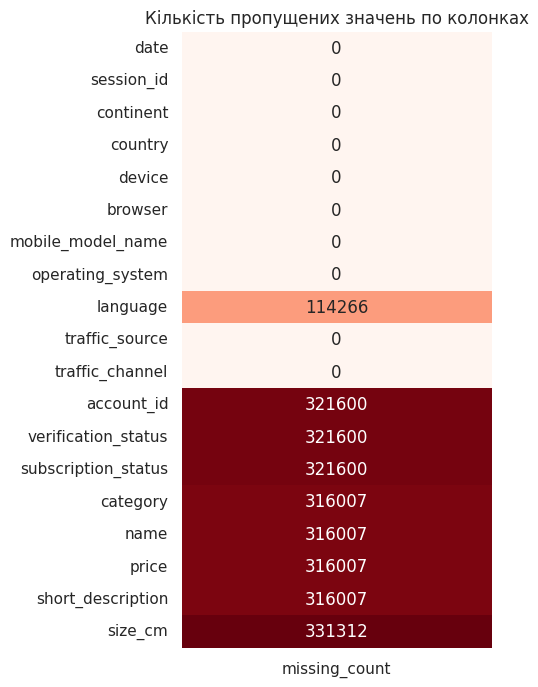

In [ ]:
missing = df.isna().sum().to_frame(name='missing_count')

plt.figure(figsize=(4, 8))
sns.heatmap(missing, annot=True, fmt='d', cmap='Reds', cbar=False)
plt.title('Кількість пропущених значень по колонках')
plt.show()

In [ ]:
registered_sessions = df.loc[df['account_id'].notna(), 'session_id'].nunique()
total_sessions = df['session_id'].nunique()
print(registered_sessions / total_sessions * 100)

7.994678796721452


## 3.3. Опис датасету

1. Загальна кількість колонок - 18 (після ознайомлення та очищення - 19)

2. Кількість колонок числового типу (та які саме) - 3, з яких дві колонки - це session_id та account_id (унікальні ідентифікатори), а ще одна - price

3. Кількість колонок категоріального типу (та які саме) - 14 (після ознайомлення та очищення - 15). Присутні такі колонки як: continent,	country,	device,	browser,	mobile_model_name,	operating_system,	language,	traffic_source,	traffic_channel, verification_status,	subscription_status,	category,	name, short_description,	size_cm,

4. Кількість колонок типу datetime - 1.

5. Кількість унікальних сесій - 349545.

6. Який період часу розглядається (від… до…) - 92 дні з 2020-11-01 до	2021-01-31

7. Чи є пропущені значення - так

8. В яких колонках більше пропущених значень, яка причина?
- В колонці language 114266 пропущених значень. Дані відсутні в датасеті, причина не відома, прийняте рішення, залишити null-значення.
- В колонках account_id,	verification_status,	subscription_status відсутні 321600 значень, адже в датасеті ми маємо досить невеликий відсоток зареєстрованих користувачів (~8%).
- В колонках category,	name,	price,	short_description відсутні 316007 значень, адже саме така кількість сесій не закінчувалась покупкою.
- В новоствореній колонці size_cm пропущених значень більше, ніж в колонці short_description, адже в описі деяких товарів не був наведений розмір.


# 4. Розвідувальний аналіз

## 4.1. Розподіл цін на товари

### 4.1.1 Яку ціну має типова покупка?

**Питання.** Як розподілені ціни товарів, які купують клієнти: переважають дешеві чи дорогі?

**Як рахуємо.** Беремо ціни з усіх рядків, де є покупка (в сесіях без покупки не має значення ціни, тому вони автоматично виключаються). Порівнюємо середнє та медіану.

In [ ]:
df['price'].describe()

,price
count,33538.000000
mean,953.298679
std,1317.001775
min,3.000000
25%,170.000000
50%,445.000000
75%,1195.000000
max,9585.000000


In [ ]:
p90 = df['price'].quantile(0.90)
print(f"90%-percentile: {p90}")

90%-percentile: 2500.0


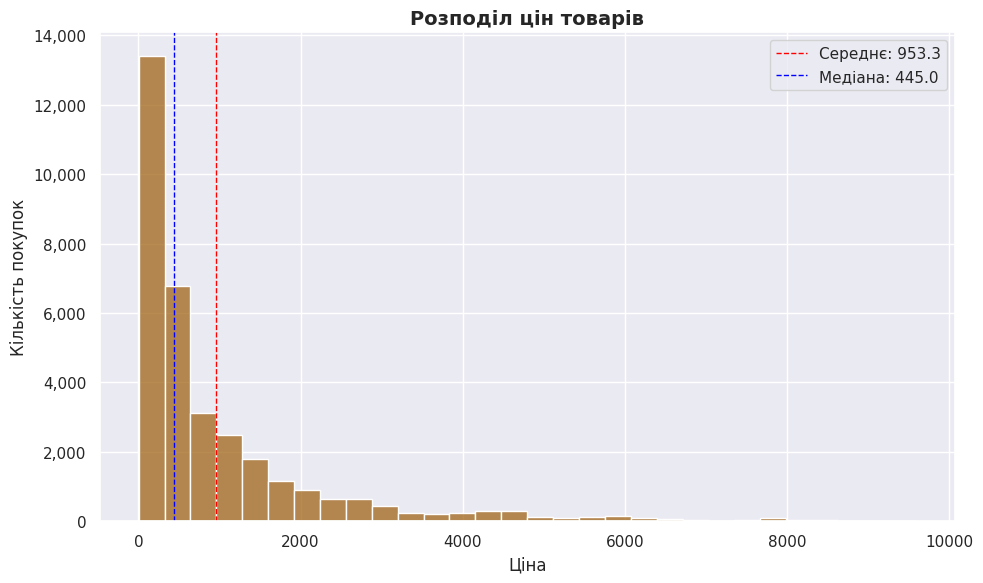

In [ ]:
mean_price = df['price'].mean()
median_price = df['price'].median()

fig, ax = plt.subplots(figsize=(10, 6))

sns.histplot(data=df, x='price', bins=30, ax=ax)

ax.axvline(mean_price, color='red', linestyle='--', linewidth=1,
           label=f'Середнє: {mean_price:,.1f}')
ax.axvline(median_price, color='blue', linestyle='--', linewidth=1,
           label=f'Медіана: {median_price:,.1f}')

ax.set_title('Розподіл цін товарів', fontsize=14, fontweight='bold')
ax.set_xlabel('Ціна')
ax.set_ylabel('Кількість покупок')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:,.0f}'))
ax.legend()

plt.tight_layout()
plt.show()

**Висновок.**
- Розподіл скошений праворуч: половина куплених товарів коштує до 445, дорогі товари (від 1195) зустрічаються в 25% покупок, а товари вище 2500 лише в 10% покупок.
- Середнє (953) значно вище за медіану (445), тобто менша кількість дорогих товарів «підтягує» середнє вгору. Для опису типової ціни купленого товару варто використовувати медіану.

### 4.1.2. Який внесок дає кожен ціновий сегмент?

**Питання.** Який внесок кожного цінового сегмента в кількість покупок і в виручку?

**Як рахуємо.**
- Покупки розбиті на цінові сегменти за перцентилями розподілу цін:
1. Дешеві: до 25-го перцентиля (до 170)
2. Середні: міжквартильний діапазон (170-1195)
3. Дорогі: між 75-м і 90-м перцентилями (1195-2500)
4. Преміум: вище 90-го перцентиля (2500+)
- Виручка сегмента - це сума цін куплених товарів у ньому.

In [ ]:
bins = [0, 170, 1195, 2500, df['price'].max()]
labels = ['Дешеві (до 170)', 'Середні (170-1195)', 'Дорогі (1195-2500)', 'Преміум (2500+)']

df['price_segment'] = pd.cut(df['price'], bins=bins, labels=labels, include_lowest=True)

seg = df.groupby('price_segment', observed=True)['price'].agg(count='count', revenue='sum')
seg['count_%'] = (seg['count'] / seg['count'].sum() * 100).round(1)
seg['revenue_%'] = (seg['revenue'] / seg['revenue'].sum() * 100).round(1)
seg

,count,revenue,count_%,revenue_%
price_segment,,,,
Дешеві (до 170),8389,623084.1,25.0,1.9
Середні (170-1195),16823,8753563.9,50.2,27.4
Дорогі (1195-2500),4994,8490971.5,14.9,26.6
Преміум (2500+),3332,14104111.6,9.9,44.1


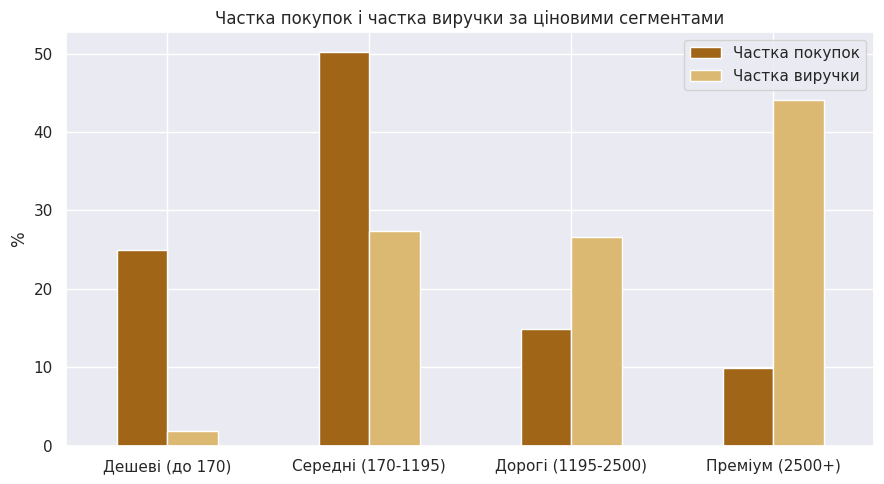

In [ ]:
seg[['count_%', 'revenue_%']].plot(kind='bar', figsize=(9, 5), rot=0)
plt.title('Частка покупок і частка виручки за ціновими сегментами')
plt.ylabel('%')
plt.xlabel('')
plt.legend(['Частка покупок', 'Частка виручки'])
plt.tight_layout()
plt.show()

**Висновок.**
- Виручка сконцентрована у верхніх сегментах: преміум-покупки (понад 2500) становлять 9.9% від усіх покупок, але приносять 44.1% виручки. Разом із дорогим сегментом (1195-2500) це 24.8% покупок і 70.7% виручки.
- Нижня чверть покупок (до 170) дає лише 1.9% виручки, а середній сегмент (170-1195) складає половину покупок і 27.4% виручки.

**Бізнес-висновок.**
- Виручка компанії сильно залежить від невеликої кількості дорогих покупок: втрата кількох преміум-продажів вплине на результат більше, ніж втрата багатьох дешевих.
- Кількість покупок сама по собі погано характеризує результат: чверть покупок майже не впливає на виручку, тому ефективність варто оцінювати за сумою продажів, а не за кількістю.
- Для перевірки далі: чи однакова така структура в різних країнах, на різних пристроях і каналах трафіку, і які категорії формують преміум-сегмент. Якщо преміум-покупки концентруються в окремих країнах чи каналах, саме туди має сенс спрямовувати зусилля.
- Обмеження: у даних немає маржі та собівартості, тож ми бачимо внесок у виручку, але не в прибуток. Дешеві покупки також можуть виконувати роль «входу» клієнта в магазин, і це за цими даними оцінити неможливо.

## 4.2. Географія продажів

**Питання.** На яких континентах і в яких країнах компанія має найбільші продажі та найбільшу кількість замовлень?

**Як рахуємо.**
- Продажі: сума цін куплених товарів.
- Замовлення: кількість рядків із покупкою. У кожній сесії міститься не більше одного товару, а кількість одиниць у даних не фіксується, тому одна покупка дорівнює одному замовленню.
- Беремо топ-3 континенти та топ-5 країн окремо за продажами й окремо за замовленнями.

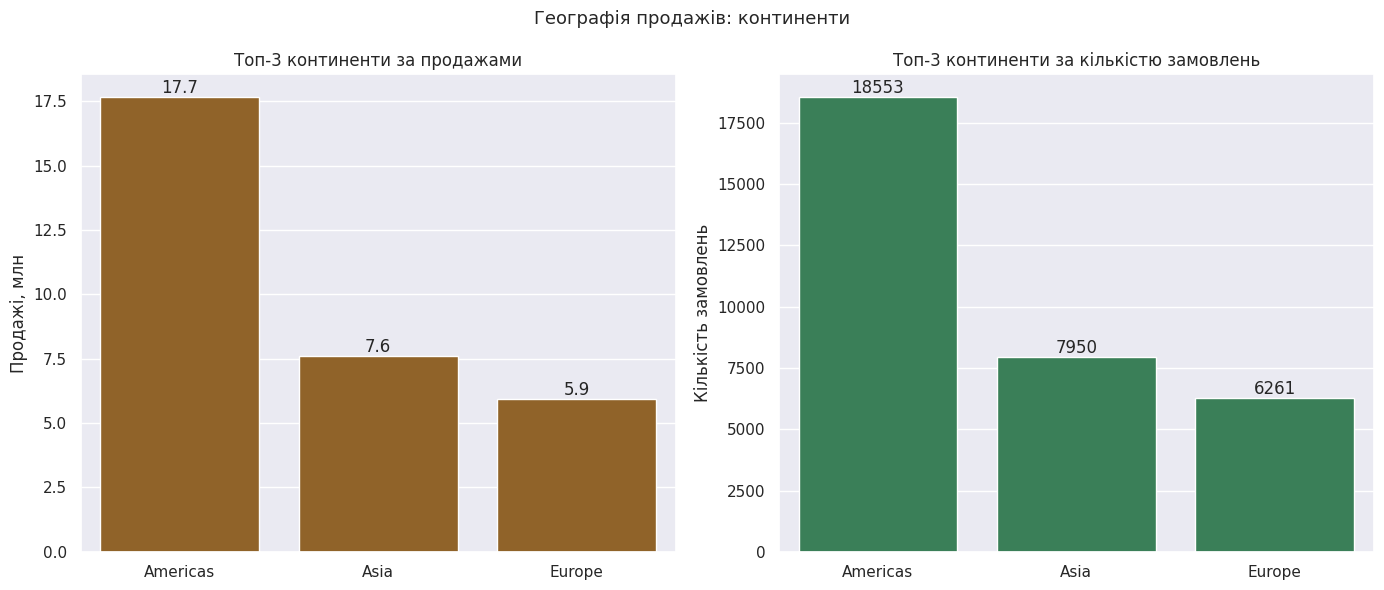

In [ ]:
# 1. Таблиця по всіх континентах
continent_stats = df.groupby('continent')['price'].agg(sales='sum', orders='count').sort_values('sales', ascending=False)

# 2. Топ-3 окремо за кожною метрикою
top_cont_sales = continent_stats.nlargest(3, 'sales')
top_cont_orders = continent_stats.nlargest(3, 'orders')

# 3. Два графіки поруч
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.barplot(x=top_cont_sales.index, y=top_cont_orders['sales'] / 1e6, ax=axes[0])
axes[0].set_title('Топ-3 континенти за продажами')
axes[0].set_xlabel('')
axes[0].set_ylabel('Продажі, млн')
axes[0].bar_label(axes[0].containers[0], fmt='%.1f')

sns.barplot(x=top_cont_sales.index, y=top_cont_orders['orders'], color='seagreen', ax=axes[1])
axes[1].set_title('Топ-3 континенти за кількістю замовлень')
axes[1].set_xlabel('')
axes[1].set_ylabel('Кількість замовлень')
axes[1].bar_label(axes[1].containers[0], fmt='%.0f')

fig.suptitle('Географія продажів: континенти', fontsize=13)
plt.tight_layout()
plt.show()

In [ ]:
continent_stats['sales_%'] = (continent_stats['sales'] / continent_stats['sales'].sum() * 100).round(1)
continent_stats['orders_%'] = (continent_stats['orders'] / continent_stats['orders'].sum() * 100).round(1)
continent_stats['avg_check'] = (continent_stats['sales'] / continent_stats['orders']).round(1)
continent_stats

,sales,orders,sales_%,orders_%,avg_check
continent,,,,,
Americas,17665280.0,18553,55.3,55.3,952.2
Asia,7601298.3,7950,23.8,23.7,956.1
Europe,5934624.2,6261,18.6,18.7,947.9
Oceania,365230.2,364,1.1,1.1,1003.4
Africa,331231.0,339,1.0,1.0,977.1
(not set),74067.4,71,0.2,0.2,1043.2


**Висновок.**
- Три континенти (Americas, Asia, Europe) дають 97.7% продажів. Америка лідирує і за виручкою - 17.7 млн (55.3% від загальних продажів), і за кількістю замовлень - 18553.
- Склад топ-3 однаковий за обома метриками, а середній чек майже не відрізняється між континентами (від 948 до 956), тобто різниця в продажах зумовлена кількістю покупок, а не ціною.
- Для перевірки далі: перевірити, чи концентрація продажів збережеться на рівні країн, чи лідерство Америки забезпечує одна країна.


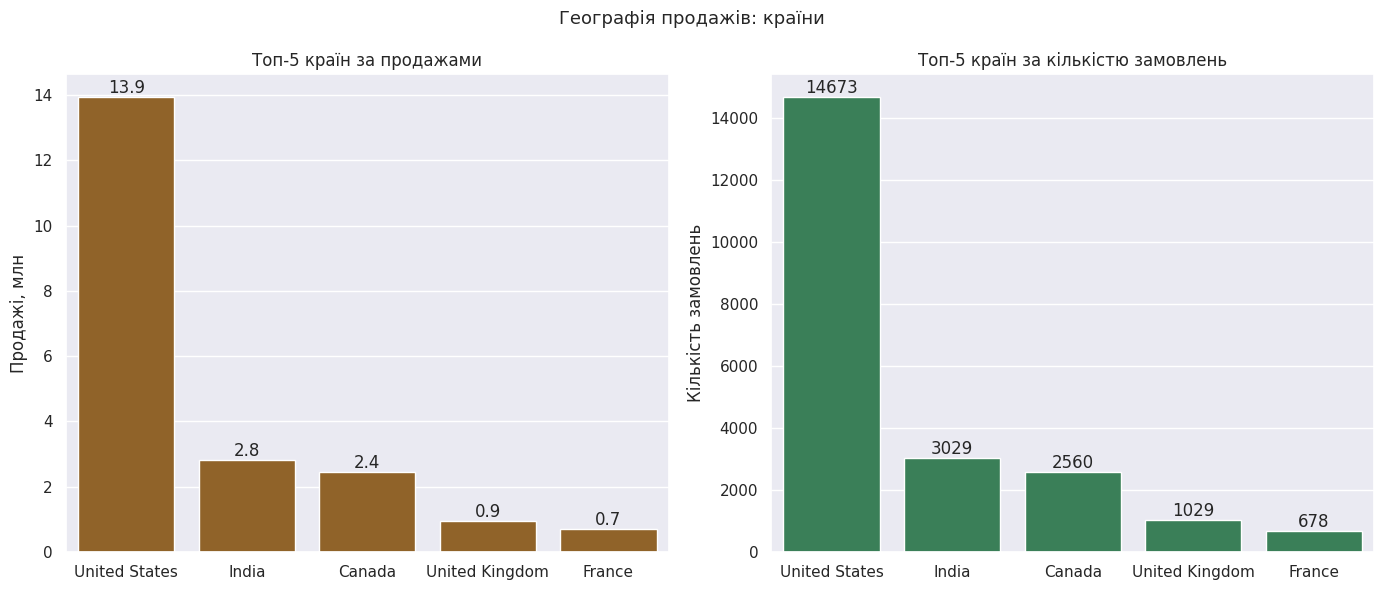

In [ ]:
# 1. Таблиця по всіх країнах
country_stats = df.groupby('country')['price'].agg(sales='sum', orders='count').sort_values('sales', ascending=False)

# 2. Топ-5 окремо за кожною метрикою
top_country_sales = country_stats.nlargest(5, 'sales')
top_country_orders = country_stats.nlargest(5, 'orders')

# 3. Два графіки поруч
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.barplot(x=top_country_sales.index, y=top_country_sales['sales'] / 1e6, ax=axes[0])
axes[0].set_title('Топ-5 країн за продажами')
axes[0].set_xlabel('')
axes[0].set_ylabel('Продажі, млн')
axes[0].bar_label(axes[0].containers[0], fmt='%.1f')

sns.barplot(x=top_country_orders.index, y=top_country_orders['orders'], color='seagreen', ax=axes[1])
axes[1].set_title('Топ-5 країн за кількістю замовлень')
axes[1].set_xlabel('')
axes[1].set_ylabel('Кількість замовлень')
axes[1].bar_label(axes[1].containers[0], fmt='%.0f')

fig.suptitle('Географія продажів: країни', fontsize=13)
plt.tight_layout()
plt.show()

In [ ]:
country_stats['sales_%'] = (country_stats['sales'] / country_stats['sales'].sum() * 100).round(1)
country_stats['orders%'] = (country_stats['orders'] / country_stats['orders'].sum() * 100).round(1)
country_stats['avg_sales'] = (country_stats['sales'] / country_stats['orders']).round(1)
country_stats

,sales,orders,sales_%,orders%,avg_sales
country,,,,,
United States,13943553.9,14673,43.6,43.8,950.3
India,2809762.0,3029,8.8,9.0,927.6
Canada,2437921.0,2560,7.6,7.6,952.3
United Kingdom,938317.9,1029,2.9,3.1,911.9
France,710692.8,678,2.2,2.0,1048.2
...,...,...,...,...,...
Bahamas,2411.0,4,0.0,0.0,602.8
Guatemala,2259.0,7,0.0,0.0,322.7
Ghana,1018.0,6,0.0,0.0,169.7


**Висновок.**
- Топ-5 країн за виручкою і за кількістю замовлень збігаються і на них припадає 65.1% виручки і 65.5% замовлень. Як і для континентів, середній чек дорівнює 912-952, що близько до середньої вартості покупок по всьому датасету.
- Найбільше замовлень (43.8%) та сума виручки (43.6%) припадає на США. Саме ця країна більшою мірою впливає на показники Американського континенту (79% виручки Америки - забезпечує США).
- Продажі в Європі та Азії розпорошені між країнами, тому топові країни вносять менший внесок в загальну виручку (наприклад: частка виручки Індії в Азії - 37%, а Великої Британії в Європі - 16%).
- Подальші кроки: перевірити, чи така сама структура категорій і цінових сегментів у США, як в інших країнах.

**Бізнес-висновок.** США є топ-країною за виручкою та кількістю замовлень, понад 40% виручки і замовлень створюють залежність і ризики, які потрібно враховувати. В Європі та Азії продажі менш сконцентровані, ніж в Америці. На топ-континентах і в топ-країнах середній чек подібний і близький до середнього по всьому датасету (953).



## 4.3. Продажі в розрізі категорій товарів


**Питання.** Які категорії товарів приносять найбільшу виручку? Чи спостерігається склад і порядок категорій в США (ключовий ринок)?

**Як рахуємо.**
- Продажі: сума цін куплених товарів.
- Беремо топ-10 категорій за виручкою по всьому датасету і окремо в США

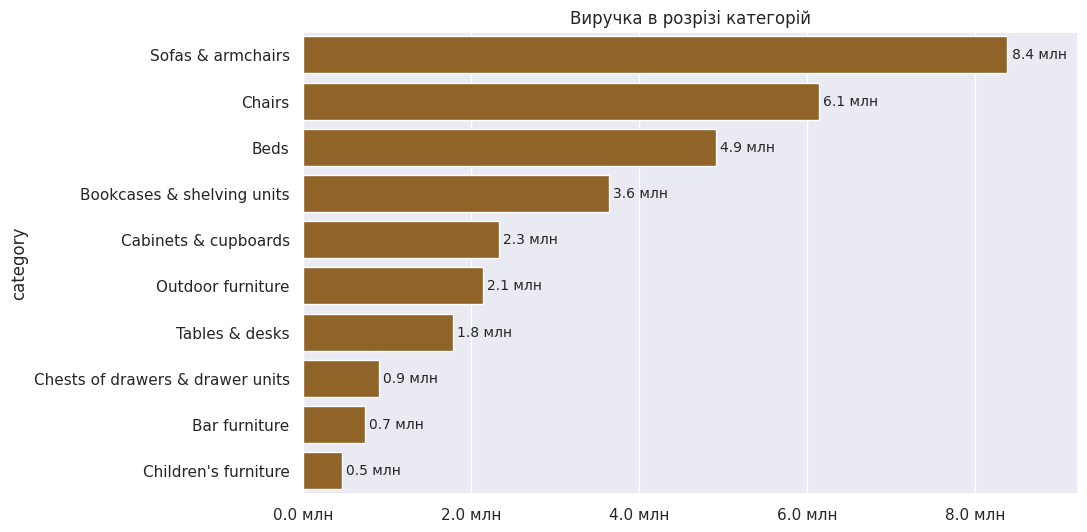

In [ ]:
# 1. Формуємо топ-10 категорій за виручкою
top_10_category = df.groupby('category')['price'].sum().sort_values(ascending=False).head(10)

# 2. Створюємо стовпчасту діаграму
fig, ax = plt.subplots(figsize=(10, 6))

ax = sns.barplot(y=top_10_category.index,
            x=top_10_category.values,
            ax=ax)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x/1e6:.1f} млн'))
ax.bar_label(
    ax.containers[0],
    labels=[f'{v/1e6:.1f} млн' for v in top_10_category.values],
    fontsize=10,
    padding=3)
plt.title("Виручка в розрізі категорій")
ax.margins(x=0.1)

plt.show()

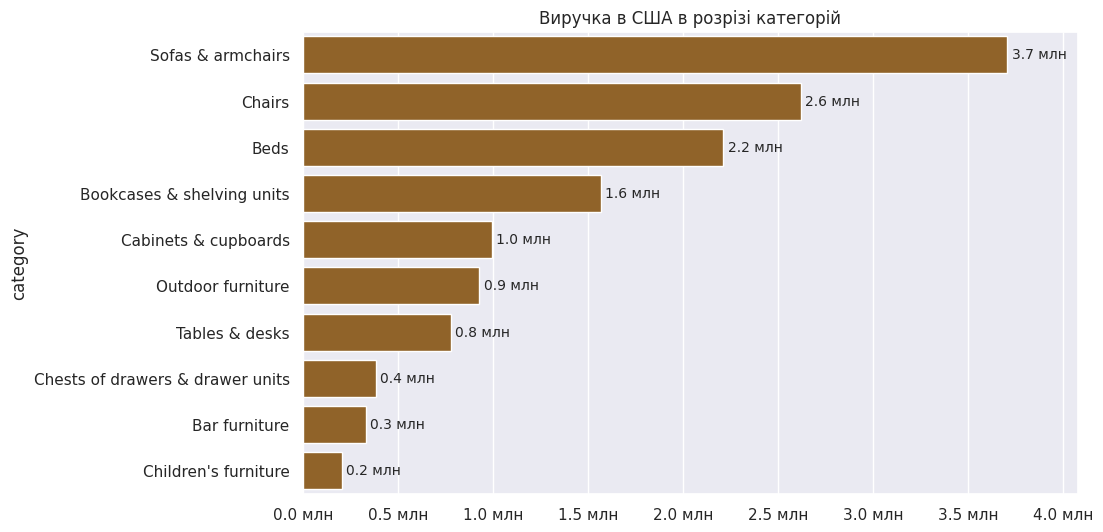

In [ ]:
# 1. Фільтруємо дані по Сполученим Штатам
df_usa = df[df['country']=='United States']

# 2. Формуємо топ-10 категорій за виручкою
top_10_category_usa = df_usa.groupby('category')['price'].sum().sort_values(ascending=False).head(10)

# 3. Створюємо стовпчасту діаграму
fig, ax = plt.subplots(figsize=(10, 6))

ax = sns.barplot(y=top_10_category_usa.index,
            x=top_10_category_usa.values,
            ax=ax)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x/1e6:.1f} млн'))
ax.bar_label(
    ax.containers[0],
    labels=[f'{v/1e6:.1f} млн' for v in top_10_category_usa.values],
    fontsize=10,
    padding=3)
plt.title("Виручка в США в розрізі категорій")
ax.margins(x=0.1)

plt.show()

**Проміжний висновок.**
- Топ-10 категорій у США збігається із загальним за складом і порядком: лідерами залишаються Sofas & armchairs, Chairs і Beds.
- Для коректного порівняння далі розглянемо частки топ-10 категорій у виручці США та решти з топ-5 країн: якщо структура справді однакова, частки будуть близькими, а помітні відхилення покажуть категорії, специфічні для США.

In [ ]:
# 1. Підготовка даних для створення зведеної таблиці
top_5_country = ['United States', 'India', 'Canada', 'United Kingdom', 'France']
df_top = df[(df['category'].isin(top_10_category.index)) & (df['country'].isin(top_5_country))]

# 2. Створення зведеної таблиці
pivot_cat = pd.pivot_table(
    df_top,
    index='category',
    columns='country',
    values='price',
    aggfunc='sum',
    fill_value=0
)

pivot_cat = pivot_cat.loc[pivot_cat.sum(axis=1).sort_values(ascending=False).index]
pivot_cat = pivot_cat[top_5_country]

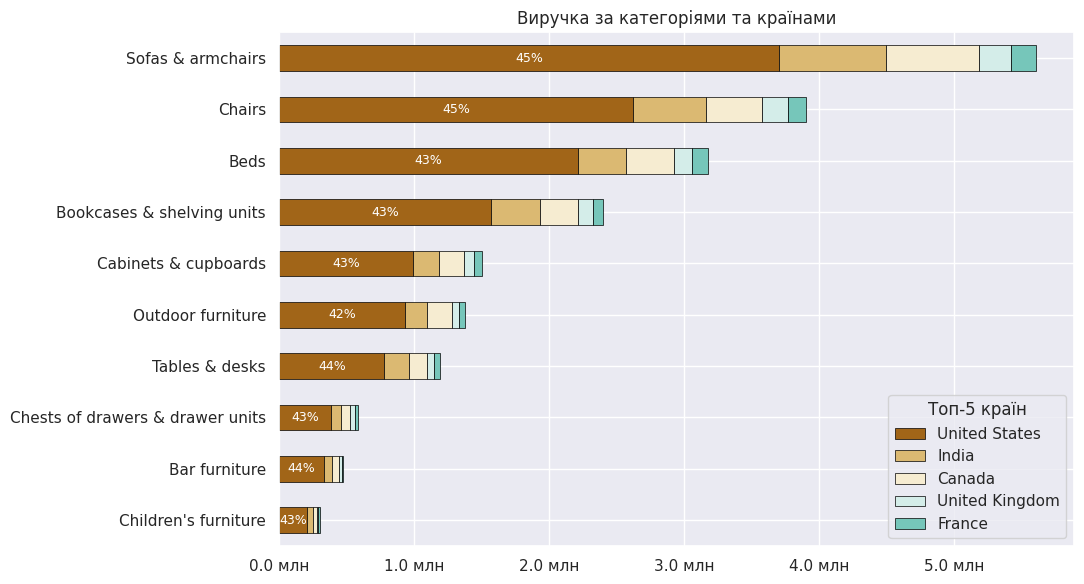

In [ ]:
cat_total = df[df['category'].isin(top_10_category.index)].groupby('category')['price'].sum()
us_share = pivot_cat['United States'] / cat_total * 100

ax = pivot_cat.plot(kind='barh', stacked=True, figsize=(11, 6), edgecolor='black', linewidth=0.5)

ax.bar_label(
    ax.containers[0],
    labels=[f'{v:.0f}%' for v in us_share],
    label_type='center',
    color='white',
    fontsize=9
)

ax.invert_yaxis()
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x/1e6:.1f} млн'))
ax.set_title('Виручка за категоріями та країнами')
ax.set_xlabel('')
ax.set_ylabel('')
ax.legend(title='Топ-5 країн')
plt.tight_layout()
plt.show()

**Висновок.**
- Топ-10 категорій у США збігається із загальним за складом і порядком, а частка США в кожній категорії 42-45% при загальній 43.6%.
- Структура категорій у США практично збігається із глобальним ринком.
- Надалі варто перевірити продажі в розрізі типу девайсу, порівняти категоріальний розподіл для різних девайсів. Чи залежить вибір категорій від пристрою з якого було здійснено покупку?

**Бізнес-висновок.** Товари категорії Sofas & armchairs, Chairs і Beds є ключовим джерелом виручки компанії (62% всієї виручки). Найвищі показники продажів ці категорії товарів демонструють як на глобальному ринку, так і на ключовому для компанії ринку США.

## 4.4. Продажі в розрізі пристрою, з якого зроблено замовлення

**Питання.** Яку частку продажів дають різні типи пристроїв? Чи відрізняється розподіл пристроїв між топ-10 категоріями товарів?

**Як рахуємо.**
- Частка продажів: сума цін куплених товарів за типом пристрою, поділена на загальну суму продажів. Модель пристрою не аналізуємо, оскільки колонка `mobile_model_name` містить неоднорідні значення.
- Розподіл пристроїв по категоріях: для кожної з топ-10 категорій рахуємо частку виручки кожного типу пристрою (кожна категорія складає 100%).

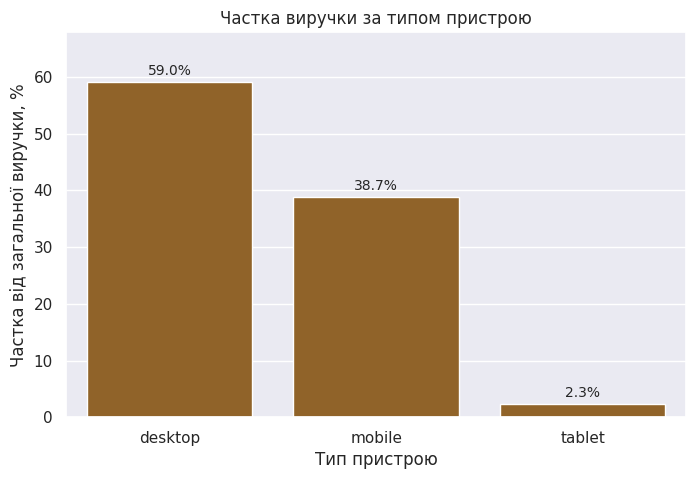

In [ ]:
device_df = df.groupby('device')['price'].sum()
device_pct = device_df / device_df.sum() * 100

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=device_pct.index, y=device_pct.values, ax=ax)

ax.bar_label(
    ax.containers[0],
    labels=[f'{p:.1f}%' for p in device_pct],
    padding=3,
    fontsize=10
)

ax.set_title('Частка виручки за типом пристрою')
ax.set_xlabel('Тип пристрою')
ax.set_ylabel('Частка від загальної виручки, %')
ax.set_ylim(0, device_pct.max() * 1.15)
plt.show()

**Проміжний висновок.** Головними джерелами виручки є пристрої desktop (59.0%) та mobile (38.7%), тоді як tablet приносить лише 2.3% виручки. Перевіримо чи збережеться таке співвідношення для різних категорій товарів.

In [ ]:
# 1. Підготовка даних для створення зведеної таблиці
df_device = df[df['category'].isin(top_10_category.index)]

# 2. Створення зведеної таблиці
pivot_device = pd.pivot_table(
    df_device,
    index='category',
    columns='device',
    values='price',
    aggfunc='sum',
    fill_value=0
)

pivot_device = pivot_device.loc[pivot_device.sum(axis=1).sort_values(ascending=False).index]

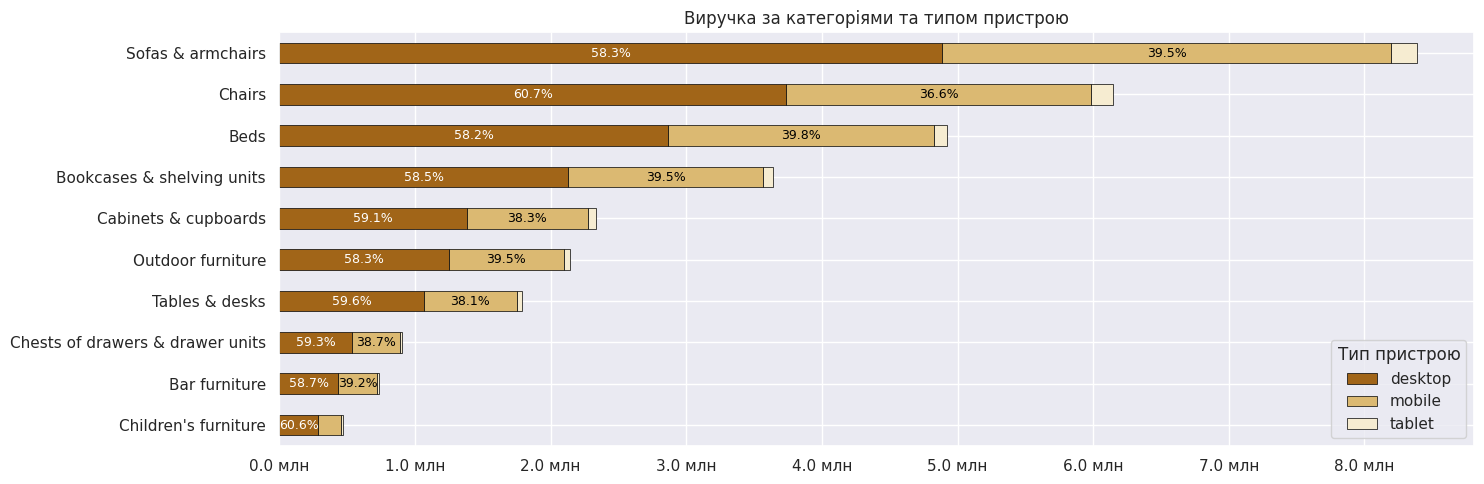

In [ ]:
pivot_device_pct = pivot_device.div(pivot_device.sum(axis=1), axis=0) * 100
ax = pivot_device.plot(kind='barh', stacked=True, figsize=(15, 5), edgecolor='black', linewidth=0.5)

min_width = pivot_device.sum(axis=1).max() * 0.03  # підписи не застосовуватимуться на сегментах, що вужчі за 3% від найдовшого стовпця

for container, col in zip(ax.containers[:2], pivot_device.columns[:2]):
    labels = [
        f'{p:.1f}%' if w > min_width else ''
        for p, w in zip(pivot_device_pct[col], pivot_device[col])
    ]
    ax.bar_label(container,
                 labels=labels,
                 label_type='center',
                 color='white' if col == 'desktop' else 'black',
                 fontsize=9)

ax.invert_yaxis()
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x/1e6:.1f} млн'))
ax.set_title('Виручка за категоріями та типом пристрою')
ax.set_ylabel('')
ax.legend(title='Тип пристрою')
plt.tight_layout()
plt.show()

**Висновок.**
- Частка desktop у всіх категоріях 58-61%, mobile 37-40%. Розподіл пристроїв по категоріях майже не відрізняється, і дуже подібний із загальним співвідношенням (59.0% на 38.7%).
- Тип пристрою, ймовірно, не впливає на вибір категорій товарів, адже розподіл типів пристрою серед різних категорій товарів дуже подібний.
- Варто перевірити джерела трафіку користувачіів, аналізуючи показники по всьому датасету та в розрізі типів пристрою. Чи впливає тип пристрою на вибір каналу трафіку?

**Бізнес-висновок.** Продажі різних категорій товарів схожі як серед різних країн, так і для різних типів пристроїв, отже структура попиту за категоріями схожа. Звідси, окремі асортиментні рішення під пристрій чи ринок за цими даними не обґрунтовані. Sofas, Chairs і Beds лишаються ядром виручки на всіх зрізах, тобто залежність від цих категорій системна, а не пов'язана з одним ринком чи пристроєм.

## 4.5. Продажі в розрізі каналів трафіку


**Питання.** Які канали трафіку приносять найбільшу виручку? Чи відрізняється розподіл типів пристроїв між каналами?

**Як рахуємо.**
- Частка виручки: сума цін куплених товарів за каналом трафіку, поділена на загальну суму продажів. Аналіз проводимо на рівні каналів трафіку (`traffic_channel`), оскільки це згрупований рівень джерел. Значення «Undefined» залишено в загальній сумі.
- Розподіл пристроїв по каналах: для кожного каналу рахуємо частку виручки кожного типу пристрою (кожен канал складає 100%).

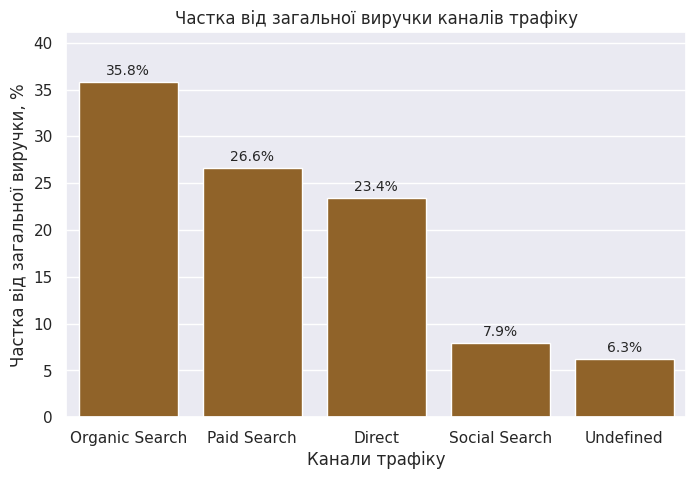

In [ ]:
channel_df = df.groupby('traffic_channel')['price'].sum().sort_values(ascending=False)
channel_pct = channel_df / channel_df.sum() * 100

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=channel_pct.index, y=channel_pct.values, ax=ax)

ax.bar_label(
    ax.containers[0],
    labels=[f'{p:.1f}%' for p in channel_pct],
    padding=3,
    fontsize=10
)

ax.set_title('Частка від загальної виручки каналів трафіку')
ax.set_xlabel('Канали трафіку')
ax.set_ylabel('Частка від загальної виручки, %')
ax.set_ylim(0, channel_pct.max() * 1.15)
plt.show()

In [ ]:
pivot_channel = pd.pivot_table(df,
                 values='price',
                 index='traffic_channel',
                 columns='device',
                 aggfunc='sum',
                 fill_value=0)

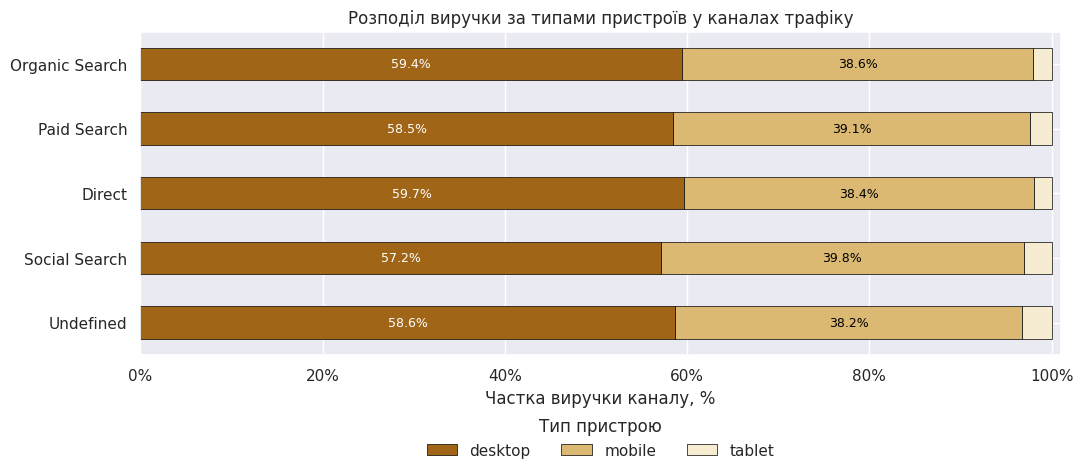

In [ ]:
channel_device_pct = pivot_channel.div(pivot_channel.sum(axis=1), axis=0) * 100
channel_device_pct = channel_device_pct.loc[channel_df.index]

fig, ax = plt.subplots(figsize=(11, 5))
channel_device_pct.plot(kind='barh', stacked=True, ax=ax, edgecolor='black', linewidth=0.5)

for container, col in zip(ax.containers[:2], channel_device_pct.columns[:2]):
    ax.bar_label(
        container,
        labels=[f'{v:.1f}%' for v in channel_device_pct[col]],
        label_type='center',
        fontsize=9,
        color='white' if col == 'desktop' else 'black'
    )

ax.invert_yaxis()
ax.set_xlim(0, 101)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0f}%'))
ax.set_title('Розподіл виручки за типами пристроїв у каналах трафіку')
ax.set_xlabel('Частка виручки каналу, %')
ax.set_ylabel('')
ax.legend(title='Тип пристрою', loc='upper center',
          bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=False)

plt.tight_layout()
plt.show()

**Висновок.**
- Органічний пошук є основним каналом за виручкою (35.8%). Платний пошук (26.6%) і прямі переходи (23.4%) разом дають ще 50%, а три канали разом 85.8%. Social Search приносить 7.9%, а невизначений канал 6.3%.
- Розподіл типів пристроїв між каналами майже однаковий: desktop становить від 57.2% до 59.7% виручки каналу, mobile від 38.2% до 39.8%, що близько до загального співвідношення (59.0% і 38.7%). Найбільше відхилення має Social Search (57.2% desktop і 39.8% mobile), але різниця з іншими каналами складає лише 2-3%.
- Отже, канал трафіку практично не пов'язаний із типом пристрою, з якого здійснюється покупка. Як і для категорій товарів, співвідношення desktop і mobile лишається майже сталим.

**Бізнес-висновок.**
- Виручка сконцентрована в трьох каналах (85.8%), тож компанія залежить від органічного пошуку, платної реклами та прямих заходів. Втрата позицій в органічній видачі або зростання вартості реклами вплине на результат найбільше.
- Платний пошук приносить понад чверть виручки, але витрати на нього в цьому датасеті не враховані, тому оцінити його окупність тут неможливо. Для такого висновку потрібні дані про витрати на рекламу.
- Тип пристрою не відрізняється між каналами, тому окремі рекламні стратегії під desktop чи mobile для окремих каналів за цими даними не підтверджуються. Різницю між каналами варто шукати в обсягах трафіку, конверсії та середньому чеку.

## 4.6. Вплив реєстрації користувачів на продажі

**Питання.**
1. Яка частка зареєстрованих користувачів підтвердила email і яка відписалась від розсилки?
2. Чи відрізняються продажі тих, хто відписався, від тих, хто досі підписаний?
3. У яких країнах найбільше зареєстрованих користувачів?

**Як рахуємо.**
- Зареєстрованими вважаємо сесії, де заповнений `account_id`. Аналіз проводиться на рівні унікальних акаунтів: нижче перевіряємо, чи кожен акаунт зустрічається в даних один раз.
- Частки підтверджених email і відписаних від розсилки рахуємо від усіх зареєстрованих акаунтів.
- Продажі підписаних і відписаних порівнюємо за сумою цін куплених товарів у їхніх сесіях, а також за кількістю покупок і середнім чеком.
- Країни порівнюємо за кількістю унікальних зареєстрованих акаунтів.

In [ ]:
# 1. Залишаємо тільки ті сесії, де є значення account_id
account_df = df[df['account_id'].notnull()]
# 2. Перевіряємо чи має один акаунт більше однієї сесії
account_df.duplicated(subset=['account_id', 'verification_status', 'subscription_status']).sum()

np.int64(0)

Кожен акаунт в датасеті має тільки одну сесію, отже переходимо до першого питання.

In [ ]:
verif = account_df['verification_status'].value_counts().to_frame('count')
verif['pct_%'] = (verif['count'] / verif['count'].sum() * 100).round(1)
verif

,count,pct_%
verification_status,,
verified,20036,71.7
unverified,7909,28.3


In [ ]:
subsc = account_df['subscription_status'].value_counts().to_frame('count')
subsc['pct_%'] = (subsc['count'] / subsc['count'].sum() * 100).round(1)
subsc

,count,pct_%
subscription_status,,
subscribed,23210,83.1
unsubscribed,4735,16.9


**Проміжний висновок.**
- Серед 27 945 зареєстрованих користувачів 28.3% не підтвердили email (понад чверть), а 16.9% відписались від розсилки.
- Непідтверджений email означає, що значна частина бази залишається недосяжною для листування, тоді як відписка стосується меншої частки.
- Далі перевіряємо, чи пов'язані ці дві ознаки: чи частіше відписуються користувачі з непідтвердженим email.

In [ ]:
pd.crosstab(account_df['verification_status'], account_df['subscription_status'])
pd.crosstab(account_df['verification_status'], account_df['subscription_status'],
            normalize='index').mul(100).round(1)

subscription_status,subscribed,unsubscribed
verification_status,,
unverified,94.6,5.4
verified,78.5,21.5


In [ ]:
# 1. Таблиця кількостей
ct = pd.crosstab(account_df['verification_status'], account_df['subscription_status'])

# 2. Тест хі-квадрат на незалежність
chi2, p, dof, expected = stats.chi2_contingency(ct)
print(f'chi2 = {chi2:.1f}, ступені свободи = {dof}, p-value = {p:.3g}')

# 3. Очікувані кількості при незалежності (перевірка умови застосування)
print(pd.DataFrame(expected, index=ct.index, columns=ct.columns).round(0))

# 4. Сила зв'язку: Cramer's V
chi2_raw = stats.chi2_contingency(ct, correction=False)[0]
n = ct.to_numpy().sum()
cramers_v = (chi2_raw / (n * (min(ct.shape) - 1))) ** 0.5
print(f"Cramér's V = {cramers_v:.3f}")

# 5. Відношення шансів відписки: verified відносно unverified
odds_verified = ct.loc['verified', 'unsubscribed'] / ct.loc['verified', 'subscribed']
odds_unverified = ct.loc['unverified', 'unsubscribed'] / ct.loc['unverified', 'subscribed']
print(f'Відношення шансів = {odds_verified / odds_unverified:.2f}')

chi2 = 1034.5, ступені свободи = 1, p-value = 5.69e-227
subscription_status  subscribed  unsubscribed
verification_status                          
unverified               6569.0        1340.0
verified                16641.0        3395.0
Cramér's V = 0.193
Відношення шансів = 4.75


**Зв'язок підтвердження email і відписки.**
- Серед зареєстрованих з підтвердженим email відписалось 21.5%, а серед тих, хто email не підтвердив, лише 5.4%. Відписки частіші в групі підтверджених.
- Імовірне пояснення: без підтвердженого email користувач, скоріш за все, не отримує розсилку й не має підстав відписуватись. Це гіпотеза, яку дані не підтверджують.
- Далі порівнюємо продажі підписаних і відписаних.

**Статистична перевірка.** Тест хі-квадрат на незалежність показав статистично значущий зв'язок (p < 0.001). Сила зв'язку слабка (Cramér's V = 0.19): частка відписаних серед підтверджених приблизно вчетверо вища, а шанс відписки вищий у 4.75 разу. Це свідчить про зв'язок, але не про причину.

In [ ]:
acc_group_df = account_df.groupby('subscription_status')['price'].agg(
    accounts='size',
    orders='count',
    sales='sum',
    avg_check='mean'
)

acc_group_df['conversion_%'] = (acc_group_df['orders'] / acc_group_df['accounts'] * 100).round(1)
acc_group_df['sales_per_account'] = (acc_group_df['sales'] / acc_group_df['accounts']).round(1)
acc_group_df['avg_check'] = acc_group_df['avg_check'].round(1)

acc_group_df

,accounts,orders,sales,avg_check,conversion_%,sales_per_account
subscription_status,,,,,,
subscribed,23210,2334,2150796.9,921.5,10.1,92.7
unsubscribed,4735,447,431721.6,965.8,9.4,91.2


**Проміжний висновок.**
- Загальні показники значно вищі в підписаних (виручка, кількість покупок), але це зумовлено розміром групи: 23 210 підписаних проти 4 735 відписаних.
- У розрахунку на акаунт групи помітно не відрізняються: конверсія у покупку 10.1% проти 9.4%, виручка на акаунт 92.7 проти 91.2.
- Середній чек у відписаних вищий приблизно на 5% (966 проти 922), але він ґрунтується лише на 447 покупках, тому надійність цієї різниці невисока.



In [ ]:
# 1. Зведена таблиця: країни × статус підтвердження
pivot_acc_country = pd.pivot_table(
    account_df,
    values='account_id',
    index='country',
    columns='verification_status',
    aggfunc='count',
    fill_value=0
)

# 2. Загальна кількість акаунтів і частки
cols = ['unverified', 'verified']
pivot_acc_country['total'] = pivot_acc_country[cols].sum(axis=1)
pivot_acc_country = pivot_acc_country.sort_values('total', ascending=False)

pivot_acc_country['share_%'] = (pivot_acc_country['total'] / pivot_acc_country['total'].sum() * 100).round(1)
pivot_acc_country['verified_%'] = (pivot_acc_country['verified'] / pivot_acc_country['total'] * 100).round(1)

top5_acc = pivot_acc_country.head(5)
top5_acc

verification_status,unverified,verified,total,share_%,verified_%
country,,,,,
United States,3495,8889,12384,44.3,71.8
India,760,1927,2687,9.6,71.7
Canada,581,1486,2067,7.4,71.9
United Kingdom,258,601,859,3.1,70.0
France,165,388,553,2.0,70.2


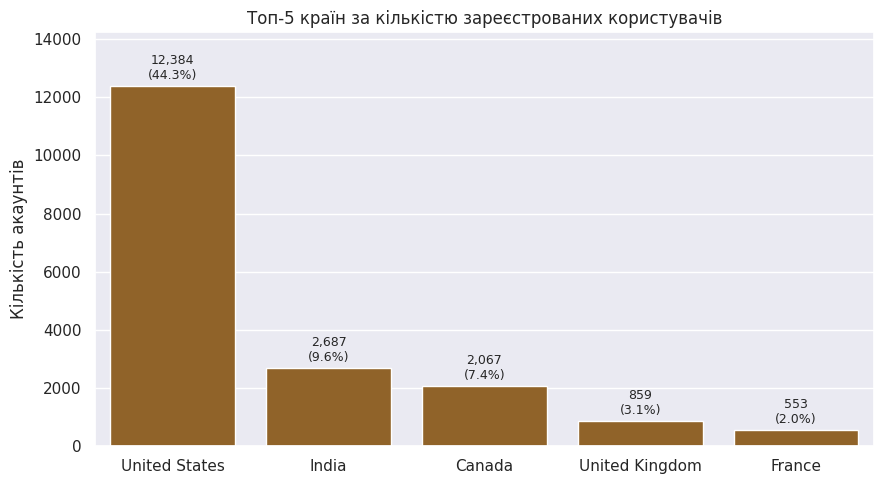

In [ ]:
# Графік топ-5 країн
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=top5_acc.index,
            y=top5_acc['total'],
            ax=ax)

ax.bar_label(
    ax.containers[0],
    labels=[f'{t:,.0f}\n({s:.1f}%)' for t, s in zip(top5_acc['total'], top5_acc['share_%'])],
    padding=3,
    fontsize=9
)

ax.set_title('Топ-5 країн за кількістю зареєстрованих користувачів')
ax.set_xlabel('')
ax.set_ylabel('Кількість акаунтів')
ax.set_ylim(0, top5_acc['total'].max() * 1.15)
plt.tight_layout()
plt.show()

**Проміжний висновок.**
- Найбільше зареєстрованих користувачів у США: 12 384 акаунти, що становить 44.3% від усіх зареєстрованих. Топ-5 країн разом дають близько 66% реєстрацій.
- Склад і порядок топ-5 за реєстраціями збігаються з топом за замовленнями та виручкою, а частка США (44.3%) майже дорівнює її частці у виручці (43.6%). Отже, реєстрації підтверджують ключові ринки.
- Частка підтверджених email майже однакова в усіх топ-5 країнах (70.0-71.9%) і близька до загальної (71.7%), тобто непідтверджений email не залежить від країни.

**Загальний висновок до розділу.**
- База зареєстрованих складається з 27 945 акаунтів. Понад чверть з них (28.3%) не підтвердили email, а 16.9% відписались від розсилки.
- Підтвердження email і відписка статистично пов'язані, але слабко (Cramér's V = 0.19): серед підтверджених відписалось 21.5%, серед непідтверджених 5.4%.
- Підписані й відписані користувачі майже не відрізняються за продажами: конверсія 10.1% проти 9.4%, виручка на акаунт 92.7 проти 91.2. Вища виручка підписаних пояснюється лише розміром групи (23 210 проти 4 735).
- Географія реєстрацій повторює географію продажів: США дають 44.3% реєстрацій (43.6% виручки), топ-5 країн збігається за складом і порядком, а частка підтверджених email у них майже однакова (70.0-71.9%).
- Загалом показники зареєстрованих лишаються подібними на різних зрізах (країна, статус підписки), а помітне зміщення пов'язане лише зі зв'язком між підтвердженням email і відпискою.

**Бізнес-висновок.**
- Проблемним місцем можна вважати непідтверджений email: майже третина зареєстрованих недосяжна для листування. Вона не залежить від країни, тож причину варто шукати в самому процесі підтвердження, а не в окремих ринках.
- Відписка від розсилки за цими даними не пов'язана зі зниженням покупок у сесії акаунта, тому сама по собі вона не є показником втрати цінного клієнта.
- Реєстрації концентровані там само, де й продажі (передусім США), тож окремих «непомічених» ринків за реєстраціями не виявлено.

## 4.7. Де трафік перетворюється на покупки?


**Питання.**
1. Яка загальна конверсія сесій у покупку?
2. Чи відрізняється конверсія за каналами трафіку, типами пристроїв і країнами?
3. Чи лідирують найбільші ринки та канали завдяки вищій конверсії, чи завдяки обсягу трафіку?

**Як рахуємо.**
- Конверсія: частка сесій із покупкою серед усіх сесій. Оскільки кожна сесія містить не більше одного товару, сесією з покупкою вважаємо сесію із заповненою ціною.
- Конверсію рахуємо окремо для кожного каналу трафіку, типу пристрою та топ-5 країн за продажами. Значення «Undefined» залишаємо як окрему групу.
- Статистичну значущість перевіряємо через 95% довірчі інтервали (метод Вілсона): якщо інтервал групи охоплює загальну конверсію, відмінність від неї вважаємо статистично не значущою.

In [ ]:
all_sessions = df['session_id'].count() # кількість всіх сесій
purchase_sessions = df['price'].notnull().sum() # кількість сесій в яких було здійснено покупку
purchase_cr = ((purchase_sessions / all_sessions) * 100).round(2)
print(f"Session-to-purchase conversion rate: {purchase_cr} %")

Session-to-purchase conversion rate: 9.59 %


In [ ]:
channel_cr = df.groupby('traffic_channel').agg(
    all_sess_channel=('session_id', 'count'),     # усі сесії каналу
    purchase_sess_channel=('price', 'count')      # сесії з покупкою
)
channel_cr['conversion_rate_%'] = (channel_cr['purchase_sess_channel'] / channel_cr['all_sess_channel'] * 100).round(2)
channel_cr = channel_cr.loc[channel_cr.sum(axis=1).sort_values(ascending=False).index]
channel_cr

,all_sess_channel,purchase_sess_channel,conversion_rate_%
traffic_channel,,,
Organic Search,124425,11921,9.58
Paid Search,94341,9042,9.58
Direct,81382,7800,9.58
Social Search,27914,2716,9.73
Undefined,21483,2059,9.58


In [ ]:
device_cr = df.groupby('device').agg(
    all_sess_device=('session_id', 'count'),     # усі сесії типу пристрою
    purchase_sess_device=('price', 'count')      # сесії з покупкою
)
device_cr['conversion_rate_%'] = (device_cr['purchase_sess_device'] / device_cr['all_sess_device'] * 100).round(2)
device_cr

,all_sess_device,purchase_sess_device,conversion_rate_%
device,,,
desktop,204429,19702,9.64
mobile,137267,13113,9.55
tablet,7849,723,9.21


In [ ]:
df_top_country = df[df['country'].isin(top_5_country)]
country_cr = df_top_country.groupby('country').agg(
    all_sess_country=('session_id', 'count'),     # усі сесії країни
    purchase_sess_country=('price', 'count')      # сесії з покупкою
)
country_cr['conversion_rate_%'] = (country_cr['purchase_sess_country'] / country_cr['all_sess_country'] * 100).round(2)
country_cr = country_cr.loc[country_cr.sum(axis=1).sort_values(ascending=False).index]
country_cr

,all_sess_country,purchase_sess_country,conversion_rate_%
country,,,
United States,153470,14673,9.56
India,32763,3029,9.25
Canada,25994,2560,9.85
United Kingdom,11003,1029,9.35
France,6958,678,9.74


**Проміжний висновок.** Загальна конверсія сесій у покупку складає 9.59%. За різними каналами трафіку, типами пристроїв і країнами конверсія сесій у покупку близька до загальної (9.21-9.85%). Для статистичної перевірки значущості використаємо довірчі інтервали (метод Вілсона).

In [ ]:
from statsmodels.stats.proportion import proportion_confint

overall_cr = df['price'].notna().sum() / len(df) * 100 # Загальна конверсія для порівняння

def add_ci(cr_df, all_col, buy_col):
    n = cr_df[all_col].astype('float64')
    k = cr_df[buy_col].astype('float64')
    low, high = proportion_confint(k, n, alpha=0.05, method='wilson')   # 95% довірчий інтервал
    cr_df['ci_low_%'] = (low * 100).round(2)
    cr_df['ci_high_%'] = (high * 100).round(2)
    cr_df['overall_in_ci'] = (cr_df['ci_low_%'] <= overall_cr) & (overall_cr <= cr_df['ci_high_%'])
    return cr_df

channel_cr = add_ci(channel_cr, 'all_sess_channel', 'purchase_sess_channel')
device_cr = add_ci(device_cr, 'all_sess_device', 'purchase_sess_device')
country_cr = add_ci(country_cr, 'all_sess_country', 'purchase_sess_country')

print(f'Загальна конверсія: {overall_cr:.2f}%')
display(channel_cr)
display(device_cr)
display(country_cr)

Загальна конверсія: 9.59%


,all_sess_channel,purchase_sess_channel,conversion_rate_%,ci_low_%,ci_high_%,overall_in_ci
traffic_channel,,,,,,
Organic Search,124425,11921,9.58,9.42,9.75,True
Paid Search,94341,9042,9.58,9.40,9.77,True
Direct,81382,7800,9.58,9.38,9.79,True
Social Search,27914,2716,9.73,9.39,10.08,True
Undefined,21483,2059,9.58,9.20,9.99,True


,all_sess_device,purchase_sess_device,conversion_rate_%,ci_low_%,ci_high_%,overall_in_ci
device,,,,,,
desktop,204429,19702,9.64,9.51,9.77,True
mobile,137267,13113,9.55,9.40,9.71,True
tablet,7849,723,9.21,8.59,9.87,True


,all_sess_country,purchase_sess_country,conversion_rate_%,ci_low_%,ci_high_%,overall_in_ci
country,,,,,,
United States,153470,14673,9.56,9.41,9.71,True
India,32763,3029,9.25,8.94,9.56,False
Canada,25994,2560,9.85,9.49,10.22,True
United Kingdom,11003,1029,9.35,8.82,9.91,True
France,6958,678,9.74,9.07,10.46,True


**Статистичний висновок.**
- Для каналів трафіку та типів пристроїв довірчі інтервали конверсії охоплюють загальну конверсію (9.59%): відмінності статистично не значущі.
- Серед топ-5 країн лише в Індії інтервал (8.94-9.56%) не охоплює загальну конверсію: вона нижча на 0.34 п.п. Різниця невелика й ледь виходить за межі інтервалу, тому її варто розглядати як слабкий сигнал, а не як доведену відмінність.

**Бізнес-висновок.**
- Загальна конверсія сесій у покупку становить 9.59%.
- Конверсія майже однакова для різних каналів (9.58-9.73%), типів пристроїв (9.21-9.64%) і країн (9.25-9.85%), тож ці чинники не впливають на конверсію. Різниця у виручці між ними зумовлена обсягом трафіку.
- Єдина помітна різниця це дещо нижча конверсія в Індії. Якби вона дорівнювала загальній, компанія отримала б приблизно 110 додаткових покупок (близько 0.3% виручки), тож це не критична втрата, але причини дані не пояснюють.

# 5. Аналіз динаміки продажів

## 5.1. Як змінюються продажі в часі?


**Питання.** Як змінюються загальні продажі за кожну дату? Чи спостерігається сезонність?

**Як рахуємо.**
- Продажі за дату: сума цін куплених товарів у сесіях цієї дати.
- Сезонність оцінюємо за динамікою продажів по днях і за середніми продажами для кожного дня тижня. Дані охоплюють лише три місяці (з 2020-11-01 по 2021-01-31), тому річну сезонність перевірити неможливо: можна оцінити лише тижневий цикл і зміни протягом цього періоду.
- Для згладжування щоденних коливань на графіку додаємо ковзне середнє за 7 днів. Цей метод допомагає прибирати ринковий шум і бачити основний тренд.

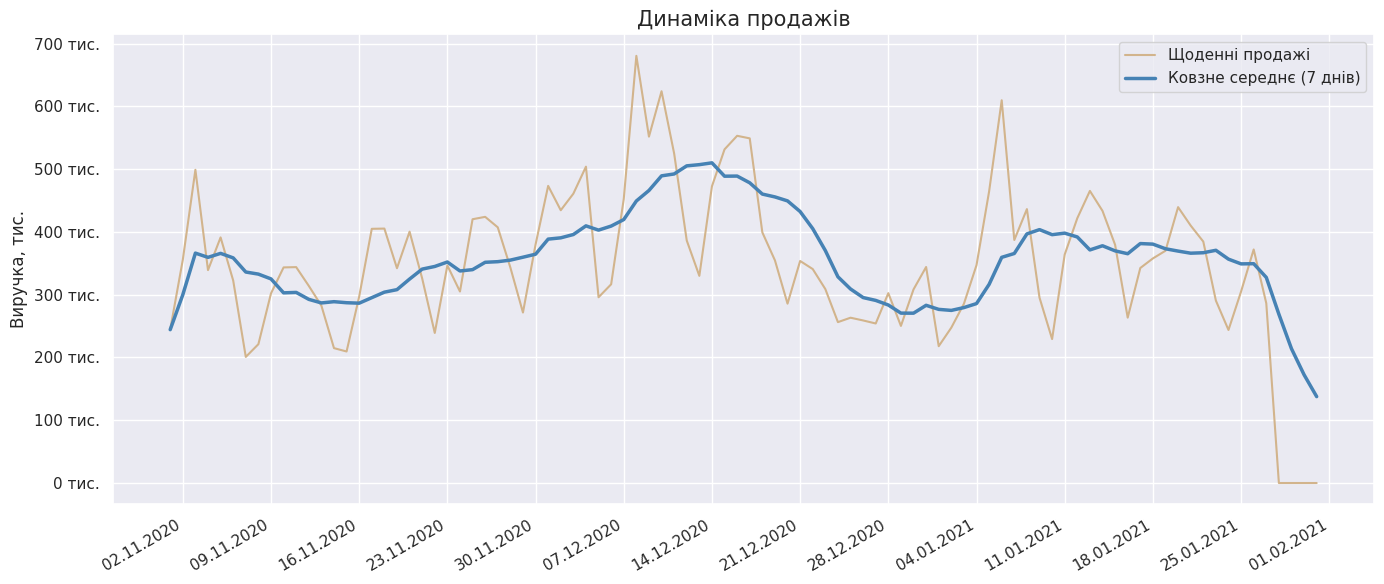

In [ ]:
import matplotlib.dates as mdates

daily_df = df.groupby('date')['price'].sum() # сума покупок за кожен день
rolling_7 = daily_df.rolling(window=7, min_periods=1).mean() # ковзне середнє за тиждень

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(daily_df, color='tan', label='Щоденні продажі')
ax.plot(rolling_7, color='steelblue', linewidth=2.5, label='Ковзне середнє (7 днів)')

ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x/1000:.0f} тис.'))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d.%m.%Y'))
ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO, interval=1))  # мітка кожен понеділок
fig.autofmt_xdate()

ax.set_title('Динаміка продажів', fontsize=15)
ax.set_xlabel('')
ax.set_ylabel('Виручка, тис.')
ax.legend()
plt.tight_layout()
plt.show()

**Проміжний висновок.**
- У листопаді продажі тримаються на стабільному рівні (ковзне середнє 290-360 тис.) без значних коливань.
- До середини грудня вони зростають до піку: ковзне середнє ≈510 тис., найвищий окремий день ≈680 тис. Окрім того, на графіку щоденних продажів помітні два дні вище 600 тис.
- До початку січня відбувається спад до ≈270 тис.
- У січні продажі частково відновлюються (≈370-400 тис.): вище листопадового рівня, але нижче грудневого піку. Окремий день на початку січня перевищує 600 тис.
- Наприкінці періоду продажі різко падають до нуля. Це схоже на особливість даних, а не на реальну динаміку, тому ці дні буде виключено з аналізу динаміки.
- Щоденна лінія хвиляста, що вказує на можливий тижневий цикл. Перевіримо це далі за днями тижня.

In [ ]:
last_sale_date = df.loc[df['price'].notna(), 'date'].max() # остання дата, коли були покупки

df_with_sales = df[df['date'] <= last_sale_date]

cut = df[df['date'] > last_sale_date]
print(f'Останній день датасету з продажами: {last_sale_date}\nКількість днів без продажів, що не враховуватимуться надалі: {cut['date'].nunique()}\nКількість сесій без покупок: {len(cut)}')

daily_df_fin = df_with_sales.groupby('date')['price'].sum()
rolling_7_fin = daily_df_fin.rolling(window=7, min_periods=1).mean()

Останній день датасету з продажами: 2021-01-27 00:00:00
Кількість днів без продажів, що не враховуватимуться надалі: 4
Кількість сесій без покупок: 13469


- Наприкінці датасету, починаючи з 2021-01-28 за чотири дні відбулось 13469 сесій без жодної покупки. Це виглядає як втрата даних про покупки, тому ці дні будуть виключені з аналізу, проте причини такої аномалії невідомі.

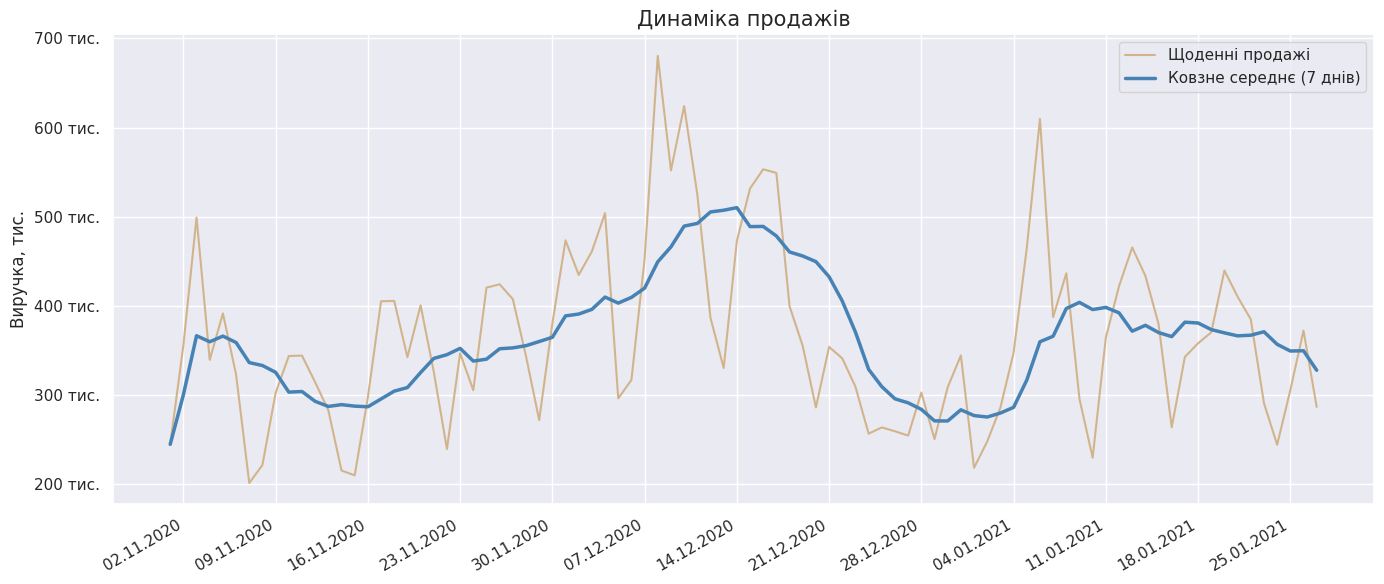

In [ ]:
fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(daily_df_fin, color='tan', label='Щоденні продажі')
ax.plot(rolling_7_fin, color='steelblue', linewidth=2.5, label='Ковзне середнє (7 днів)')

ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x/1000:.0f} тис.'))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d.%m.%Y'))
ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO, interval=1))
fig.autofmt_xdate()

ax.set_title('Динаміка продажів', fontsize=15)
ax.set_xlabel('')
ax.set_ylabel('Виручка, тис.')
ax.legend()
plt.tight_layout()
plt.show()

,mean,std,count
weekday,,,
Пн,356637.7,54441.1,13
Вт,419808.9,112001.5,13
Ср,420503.3,103651.5,13
Чт,411411.3,100509.6,12
Пт,376922.3,92270.7,12
Сб,289832.6,56190.3,12
Нд,267183.7,42501.3,13


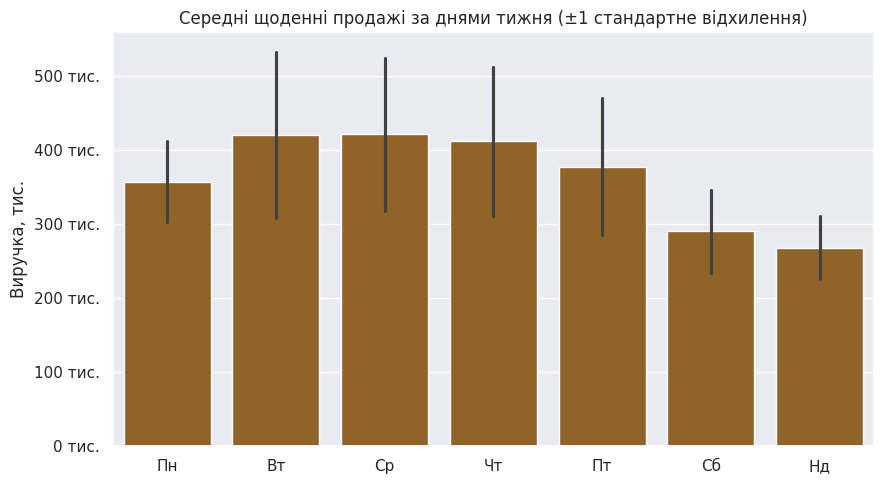

In [ ]:
day_names = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Нд']

weekday_df = daily_df_fin.to_frame('sales')
weekday_df['weekday'] = weekday_df.index.dayofweek.map(dict(enumerate(day_names)))
weekday_df['weekday'] = pd.Categorical(weekday_df['weekday'], categories=day_names, ordered=True)

# таблиця: середнє, розкид і кількість днів для кожного дня тижня
weekday_stats = weekday_df.groupby('weekday', observed=True)['sales'].agg(['mean', 'std', 'count']).round(1)
display(weekday_stats)

# графік: середнє з розкидом (±1 стандартне відхилення)
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=weekday_df, x='weekday', y='sales', order=day_names,
            estimator='mean', errorbar='sd', ax=ax)

ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x/1000:.0f} тис.'))
ax.set_title('Середні щоденні продажі за днями тижня (±1 стандартне відхилення)')
ax.set_xlabel('')
ax.set_ylabel('Виручка, тис.')
plt.tight_layout()
plt.show()

**Проміжний висновок.**
- Спостерігається тижнева періодичність: середні щоденні продажі найвищі у вівторок-четвер (≈410-420 тис.), у понеділок і п'ятницю нижчі (≈360-380 тис.), а найнижчі у вихідні (субота ≈290 тис., неділя ≈270 тис.).
- Розкид продажів усередині кожного дня тижня значний (12-13 спостережень для кожного дня тижня), тому статистичну значущість цих відмінностей потрібно перевірити окремо.

In [ ]:
# 1. Продажі за днями тижня: сім груп
week_groups = [g['sales'].values for _, g in weekday_df.groupby('weekday', observed=True)]

# 2. Краскела-Уолліса
H, p = stats.kruskal(*week_groups)
n, k = len(weekday_df), len(week_groups)
eps_sq = (H - k + 1) / (n - k)
print(f'Краскела-Уолліса: H = {H:.2f}, p-value = {p:.4f}, епсилон-квадрат = {eps_sq:.3f}')

# 3. Будні проти вихідних
weekend = weekday_df.loc[weekday_df['weekday'].isin(['Сб', 'Нд']), 'sales']
workdays = weekday_df.loc[~weekday_df['weekday'].isin(['Сб', 'Нд']), 'sales']

U, p_u = stats.mannwhitneyu(workdays, weekend, alternative='two-sided')
rbc = 2 * U / (len(workdays) * len(weekend)) - 1
print(f'Манна-Уїтні: U = {U:.0f}, p-value = {p_u:.4f}, rank-biserial = {rbc:.2f}')
print(f'Медіана будні: {workdays.median():,.0f}, вихідні: {weekend.median():,.0f}')

Краскела-Уолліса: H = 34.47, p-value = 0.0000, епсилон-квадрат = 0.351
Манна-Уїтні: U = 1392, p-value = 0.0000, rank-biserial = 0.77
Медіана будні: 384,615, вихідні: 271,602


**Проміжний висновок.**
- Різниця між днями тижня статистично значуща (тест Краскела-Уолліса, p < 0.001, ефект сильний: епсилон-квадрат = 0.35).
- Вихідні помітно нижчі за будні: медіана щоденних продажів ≈272 тис. проти ≈385 тис., тобто приблизно на 29% менше (тест Манна-Уїтні, p < 0.001, rank-biserial = 0.77). Випадково обраний будній день перевищує вихідний приблизно у 88% випадків.
- Тест не вказує, які саме дні відрізняються між собою, тому твердження про окремі будні (наприклад, понеділок чи п'ятницю) носять лише описовий характер.

**Загальний висновок: динаміка продажів.**
- Продажі коливаються навколо ≈290-400 тис. на день із виразним піком у першій половині грудня (ковзне середнє ≈510 тис., найвищий день ≈680 тис.), спадом до ≈270 тис. на межі грудня й січня та частковим відновленням у січні (≈370-400 тис.).
- Поверх загальної хвилі діє стійкий тижневий цикл: найвищі продажі у вівторок-четвер (≈410-420 тис.), найнижчі у вихідні (≈270-290 тис.). Різниця статистично значуща й сильна: медіана вихідних приблизно на 29% нижча за медіану будніх днів.
- Чотири останні дні (28-31.01.2021) виключено з аналізу, бо в них немає жодної покупки при нормальному трафіку (13469 сесій).

**Бізнес-висновок.**
- Продажі нерівномірні в часі: найбільше виручки припадає на будні (особливо вівторок-четвер) та на першу половину грудня, тож навантаження на склад, логістику й підтримку варто планувати з урахуванням цього графіка.
- Вихідні дають помітно менше продажів, тому саме в них є запас для зростання (наприклад, через таргетовані акції). Чи спрацює такий підхід, ці дані не підтверджують.
- Причини грудневого піку й спаду перед Новим роком дані не пояснюють, тому прив'язувати їх до акцій чи свят без додаткової інформації не можна. Спостереження охоплює один сезон (три місяці), тож повторюваність цього піку в інші роки перевірити неможливо.

## 5.2. Динаміка продажів за континентами

**Питання.** Як змінюються продажі за кожну дату на різних континентах?

**Як рахуємо.**
- Продажі за дату: сума цін куплених товарів у сесіях цієї дати згруповані за трьома континентами (Америка, Азія та Європа).
- Будуємо лінійний графік з щоденними коливаннями продажів, а також ковзним середнім для кожного континенту.

In [ ]:
top_3_cont = ['Americas', 'Asia', 'Europe']

# Створюємо зведену таблицю з продажами на топ-3 континентах за кожну дату
cont_daily_df = pd.pivot_table(
    df_with_sales[df_with_sales['continent'].isin(top_3_cont)],
    values='price',
    index='date',
    columns='continent',
    aggfunc='sum',
    fill_value=0
)

cont_daily_df = cont_daily_df[top_3_cont]
cont_rolling = cont_daily_df.rolling(window=7, min_periods=1).mean()

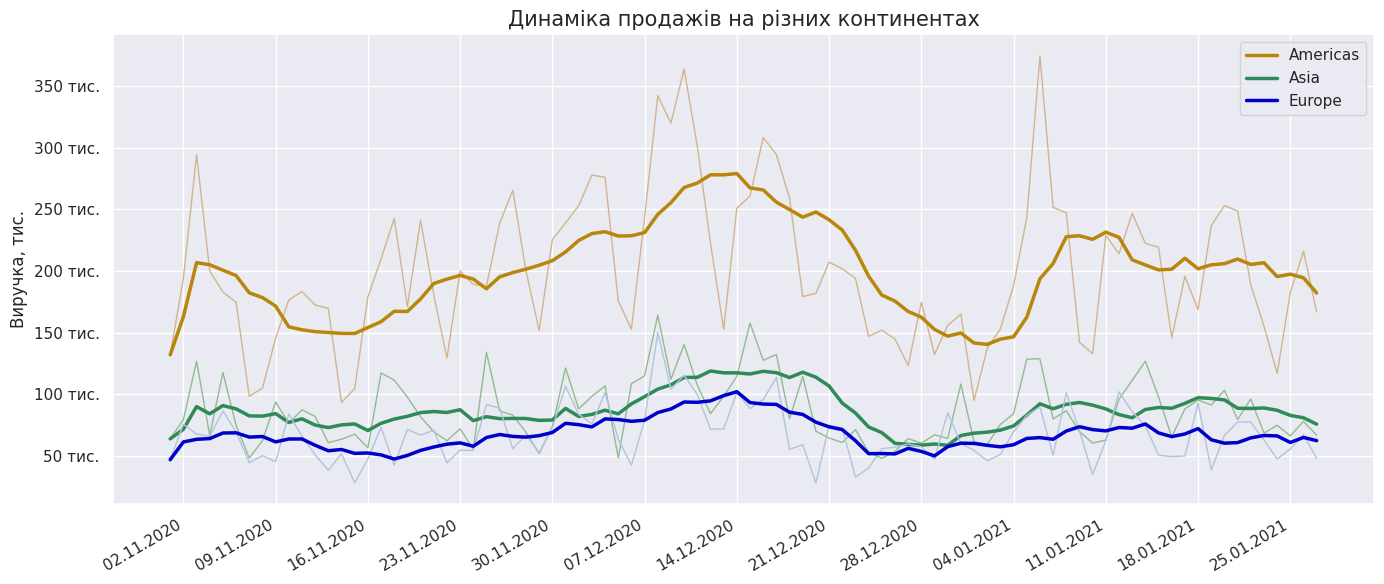

In [ ]:
colors = {
    'Americas': {'raw': 'tan', 'rolling': 'darkgoldenrod'},
    'Asia':     {'raw': 'darkseagreen', 'rolling': 'seagreen'},
    'Europe':   {'raw': 'lightsteelblue', 'rolling': 'mediumblue'},
}

fig, ax = plt.subplots(figsize=(14, 6))
for cont in top_3_cont:
    ax.plot(cont_daily_df.index, cont_daily_df[cont],
            color=colors[cont]['raw'], linewidth=1, label='_nolegend_')
    ax.plot(cont_rolling.index, cont_rolling[cont],
            color=colors[cont]['rolling'], linewidth=2.5, label=cont)

ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x/1000:.0f} тис.'))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d.%m.%Y'))
ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO, interval=1))
fig.autofmt_xdate()

ax.set_title('Динаміка продажів на різних континентах', fontsize=15)
ax.set_xlabel('')
ax.set_ylabel('Виручка, тис.')
ax.legend()
plt.tight_layout()
plt.show()

**Проміжний висновок.**
- Америка лідирує за рівнем продажів: ковзне середнє ≈140-280 тис. на день проти ≈50-120 тис. в Азії та ≈50-100 тис. у Європі. Щоденна лінія Америки двічі перевищує 350 тис. (середина грудня й початок січня).
- У всіх трьох континентів форма динаміки однакова й повторює загальну: зростання до піку в першій половині грудня, спад до початку січня й часткове відновлення. Відносно власного рівня піки й провали подібні (приблизно вдвічі), а більші абсолютні коливання Америки зумовлені загально вищими продажами (17.7 млн проти 13.5 млн в Азії та Європі разом).
- Азія тримається вище Європи протягом усього періоду, але лінії рухаються паралельно, а щоденні значення Азії та Європи постійно переплітаються.

In [ ]:
cont_stats = pd.DataFrame({
    'mean': cont_daily_df.mean(),
    'median': cont_daily_df.median(),
    'std': cont_daily_df.std(),
    'min': cont_daily_df.min(),
    'max': cont_daily_df.max(),
})
cont_stats['cv_%'] = (cont_stats['std'] / cont_stats['mean'] * 100).round(1)
cont_stats.round(0)


,mean,median,std,min,max,cv_%
continent,,,,,,
Americas,200742.0,188963.0,60264.0,93309.0,374615.0,30.0
Asia,86378.0,80046.0,26373.0,48001.0,164165.0,30.0
Europe,67439.0,66325.0,22205.0,27976.0,150175.0,33.0


- Відносна мінливість щоденних продажів майже однакова для всіх трьох континентів: коефіцієнт варіації становить 30% в Америці, 30% в Азії та 33% у Європі. Більші абсолютні коливання Америки (стандартне відхилення ≈60 тис.) зумовлені її масштабом (середній день ≈201 тис.), а не більшою нестабільністю.

**Загальний висновок: динаміка продажів за континентами.**
- Америка лідирує за рівнем продажів: ковзне середнє ≈140-280 тис. на день проти ≈50-120 тис. в Азії та ≈50-100 тис. у Європі (середній день ≈201, ≈86 і ≈67 тис. відповідно).
- Форма динаміки в усіх трьох континентів однакова й повторює загальну: зростання до піку в першій половині грудня, спад до початку січня й часткове відновлення. Відносно власного рівня піки й провали подібні.
- Відносна мінливість щоденних продажів майже однакова: коефіцієнт варіації 30% в Америці, 30% в Азії та 33% у Європі. Більші абсолютні коливання Америки (стандартне відхилення ≈60 тис.) пояснюються її масштабом, а не більшою нестабільністю.
- Азія тримається вище Європи протягом усього періоду, але їхні лінії рухаються паралельно.

**Бізнес-висновок.**
- Динаміка продажів на різних континентах визначається спільним фактором: усі три континенти реагують на загальну хвилю (грудневий підйом, спад до Нового року) однаково, тож окремих регіональних сезонних особливостей за цими даними не виявлено.
- Розрив між континентами це різниця в масштабі продажів (США дають понад 40% виручки), а не в характері попиту.
- Причини спільної хвилі дані не пояснюють. Чи зумовлена вона загальними акціями чи сезонністю, з цього датасету встановити неможливо.

## 5.3. Динаміка продажів за каналами трафіку

**Питання.** Як змінюються продажі за кожну дату з різних каналів трафіку?

**Як рахуємо.**
- Продажі за дату: сума цін куплених товарів у сесіях цієї дати згруповані за каналами трафіку.
- Будуємо лінійний графік з щоденними коливаннями продажів, а також ковзним середнім для кожного каналу трафіку.

In [ ]:
# Створюємо зведену таблицю з продажами за різними каналами трафіку за кожну дату
channel_daily_df = pd.pivot_table(
    df_with_sales,
    values='price',
    index='date',
    columns='traffic_channel',
    aggfunc='sum',
    fill_value=0
)

channel_order = channel_daily_df.sum().sort_values(ascending=False).index
channel_daily_df = channel_daily_df[channel_order]
channel_rolling = channel_daily_df.rolling(window=7, min_periods=1).mean()

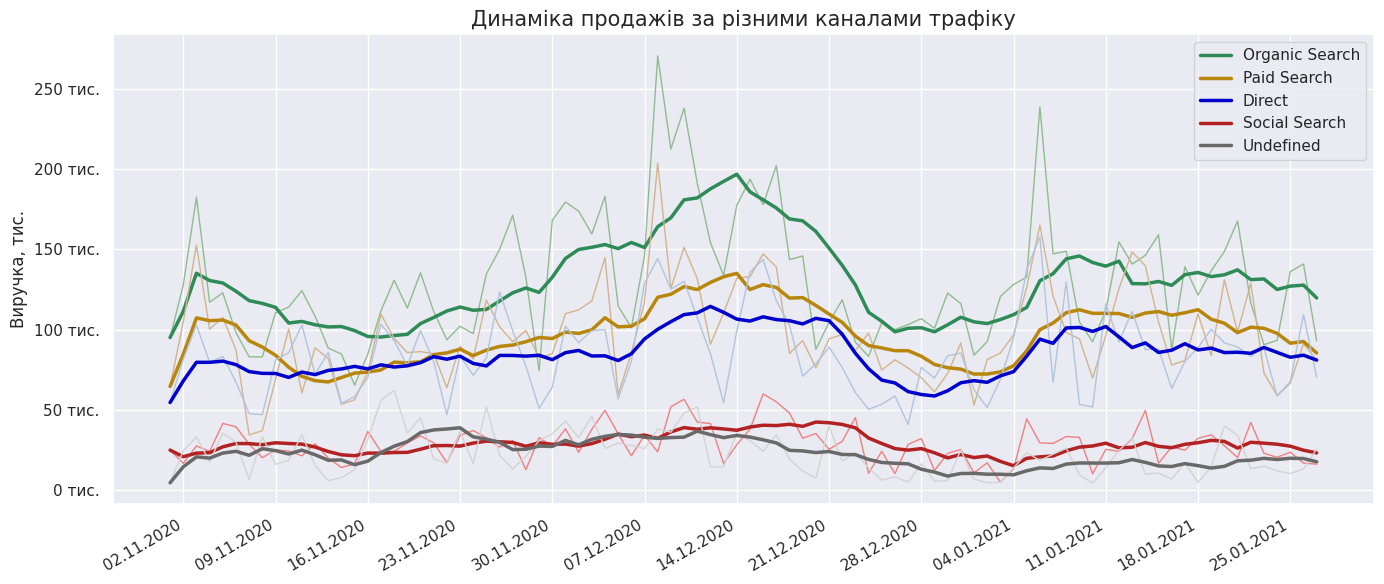

In [ ]:
colors_channel = {
    'Organic Search': {'raw': 'darkseagreen',   'rolling': 'seagreen'},
    'Paid Search':    {'raw': 'tan',            'rolling': 'darkgoldenrod'},
    'Direct':         {'raw': 'lightsteelblue', 'rolling': 'mediumblue'},
    'Social Search':  {'raw': 'lightcoral',     'rolling': 'firebrick'},
    'Undefined':      {'raw': 'lightgray',      'rolling': 'dimgray'},
}

fig, ax = plt.subplots(figsize=(14, 6))
for channel in channel_daily_df:
    ax.plot(channel_daily_df.index, channel_daily_df[channel],
            color=colors_channel[channel]['raw'], linewidth=1, label='_nolegend_')
    ax.plot(channel_rolling.index, channel_rolling[channel],
            color=colors_channel[channel]['rolling'], linewidth=2.5, label=channel)

ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x/1000:.0f} тис.'))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d.%m.%Y'))
ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO, interval=1))
fig.autofmt_xdate()

ax.set_title('Динаміка продажів за різними каналами трафіку', fontsize=15)
ax.set_xlabel('')
ax.set_ylabel('Виручка, тис.')
ax.legend()
plt.tight_layout()
plt.show()

**Висновок.**
- Рівні продажів за каналами (за ковзним середнім): Organic ≈90-200 тис. на день, Paid ≈65-135 тис., Direct ≈55-115 тис., Social Search ≈15-45 тис., Undefined ≈10-40 тис.
- Порядок каналів переважно повторює їхній порядок за сумою виручки й кількістю сесій (Organic > Paid > Direct, далі з великим відривом Social Search і Undefined). Водночас лінії Paid і Direct місцями близькі (друга половина листопада, початок січня), а Social Search і Undefined перетинаються (особливо до середини грудня).
- Три найбільші канали мають ту саму форму динаміки, що й весь датасет та окремі континенти: пік у першій половині грудня, провал на межі грудня й січня, часткове відновлення в січні. У Social Search і Undefined грудневий підйом майже не видно, а їхні щоденні значення дуже шумні відносно невеликого рівня.

**Бізнес-висновок.**
- Канали рухаються разом, тож динаміку продажів задає спільний фактор (загальна хвиля попиту), а не окремий канал. Така сама картина була й на рівні континентів.
- Різниця між каналами це різниця в обсязі трафіку, а не в якості: у розділі про конверсію показник майже однаковий в усіх каналах, тож канали мають різну вагу, але однаково перетворюють трафік на покупки.
- Основну частину виручки дають пошукові канали (Organic і Paid), тому результат залежить від позицій у пошуку й від рекламної активності. Грудневий пік платного каналу збігається з органічним, проте ці дані не дозволяють сказати, чи реклама сама його створила.
- Графік показує виручку, а не витрати на рекламу, тому ефективність платного каналу з цих даних оцінити неможливо.

## 5.4. Динаміка продажів за типом пристрою

**Питання.** Як змінюються продажі за кожну дату для різних типів пристрою?

**Як рахуємо.**
- Продажі за дату: сума цін куплених товарів у сесіях цієї дати згруповані за типами пристрою.
- Будуємо лінійний графік з щоденними коливаннями продажів, а також ковзним середнім для кожного типу пристрою.

In [ ]:
# Створюємо зведену таблицю з продажами з різних типів пристрою за кожну дату
device_daily_df = pd.pivot_table(
    df_with_sales,
    values='price',
    index='date',
    columns='device',
    aggfunc='sum',
    fill_value=0
)

device_order = device_daily_df.sum().sort_values(ascending=False).index
device_daily_df = device_daily_df[device_order]
device_rolling = device_daily_df.rolling(window=7, min_periods=1).mean()

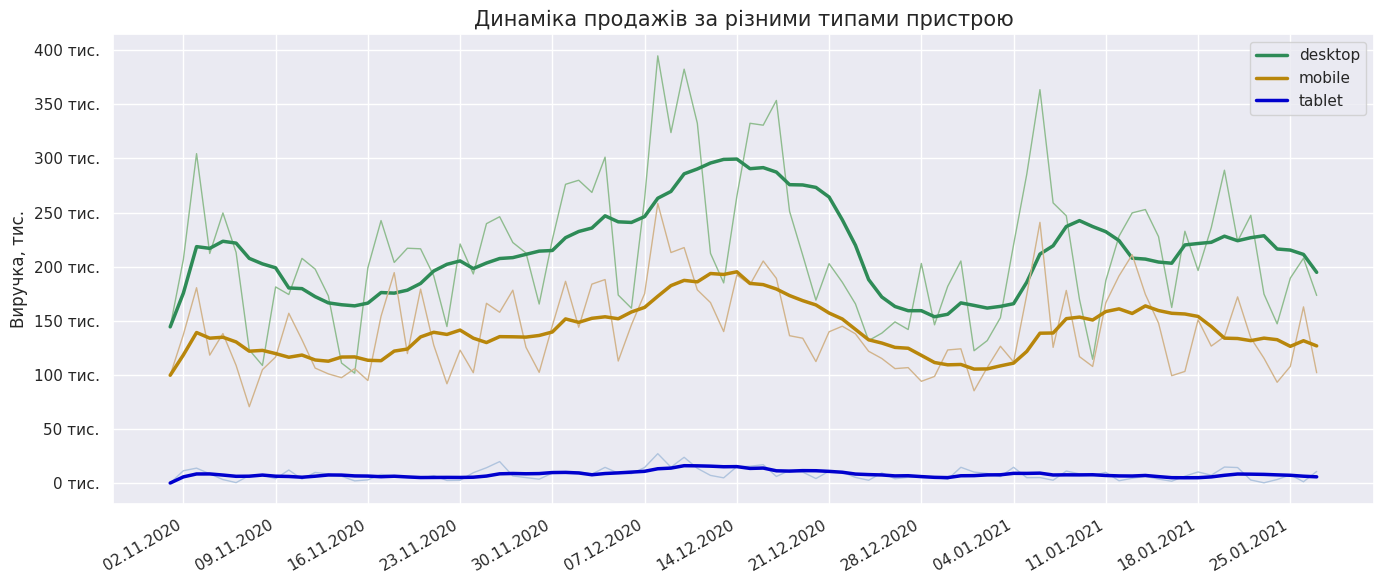

In [ ]:
colors_device = {
    'desktop': {'raw': 'darkseagreen', 'rolling': 'seagreen'},
    'mobile': {'raw': 'tan', 'rolling': 'darkgoldenrod'},
    'tablet': {'raw': 'lightsteelblue', 'rolling': 'mediumblue'},
}

fig, ax = plt.subplots(figsize=(14, 6))
for device in device_daily_df:
    ax.plot(device_daily_df.index, device_daily_df[device],
            color=colors_device[device]['raw'], linewidth=1, label='_nolegend_')
    ax.plot(device_rolling.index, device_rolling[device],
            color=colors_device[device]['rolling'], linewidth=2.5, label=device)

ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x/1000:.0f} тис.'))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d.%m.%Y'))
ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO, interval=1))
fig.autofmt_xdate()

ax.set_title('Динаміка продажів за різними типами пристрою', fontsize=15)
ax.set_xlabel('')
ax.set_ylabel('Виручка, тис.')
ax.legend()
plt.tight_layout()
plt.show()

**Висновок.**
- Рівні продажів за типами пристрою (за ковзним середнім): desktop ≈160-300 тис. на день, mobile ≈100-200 тис., tablet ≲20 тис.
- Порядок типів пристроїв повторює їхній порядок за сумою виручки й кількістю сесій (desktop > mobile, далі з великим відривом tablet). Desktop впродовж усього періоду приносить найбільшу виручку, хоча в окремі дні щоденні лінії desktop і mobile перетинаються.
- Desktop і mobile мають ту саму форму динаміки, що й весь датасет, окремі континенти та канали трафіку: пік у першій половині грудня, провал на межі грудня й січня, часткове відновлення в січні. У tablet щоденні значення дуже низькі та шумні відносно невеликого рівня.

**Бізнес-висновок.**
- Динаміку продажів визначає спільна хвиля попиту, а не окремий тип пристрою: desktop і mobile рухаються разом, а їхнє співвідношення (приблизно 60% до 40% виручки) майже не змінюється протягом періоду. Така сама картина була для континентів і каналів трафіку.
- Різниця між пристроями це різниця в обсязі, а не в якості трафіку: конверсія сесій у покупку майже однакова (desktop 9.64%, mobile 9.55%, tablet 9.21%). Втрата мобільного трафіку мала б приблизно таку саму вагу в розрахунку на сесію, що й втрата десктопного.
- Планшети дають близько 2% виручки, тому їхня динаміка не впливає на загальний результат і не потребує окремих рішень.

## Висновок з динаміки продажів

**Загальний висновок до розділу: динаміка продажів.**
- Продажі коливаються навколо ≈290-400 тис. на день: виразний пік у першій половині грудня (ковзне середнє ≈510 тис., найвищий день ≈680 тис.), спад до ≈270 тис. на межі грудня й січня та часткове відновлення в січні.
- Поверх цієї хвилі діє стійкий тижневий цикл: найвищі продажі у вівторок-четвер, найнижчі у вихідні. Різниця статистично значуща й сильна (медіана вихідних приблизно на 29% нижча за будні).
- Усі зрізи (континенти, канали трафіку, типи пристроїв) мають ту саму форму динаміки: грудневий пік, провал на межі грудня й січня, відновлення в січні. Відрізняється лише масштаб: Америка, Organic Search і desktop лідирують, а дрібні групи (Social Search, Undefined, tablet) мають слабший підйом і шумніші щоденні значення.
- Відносна мінливість продажів за континентами майже однакова (коефіцієнт варіації 30-33%): більші абсолютні коливання Америки пояснюються її масштабом.
- Аналіз охоплює 88 днів (01.11.2020-27.01.2021): останні 4 дні виключено, бо в них немає покупок при нормальному трафіку (13 469 сесій). Дані охоплюють лише три місяці, тому річну сезонність перевірити неможливо.

**Бізнес-висновок.**
- Динаміку продажів задає спільний фактор (загальна хвиля попиту), а не окремий регіон, канал чи пристрій: усі зрізи рухаються разом. Різниця між групами це різниця в обсязі, а не в характері попиту; для каналів і пристроїв це підтверджується майже однаковою конверсією (розділ 4.7).
- Навантаження на склад, логістику й підтримку варто планувати з урахуванням тижневого циклу (пік у вівторок-четвер) і грудневого підйому. Вихідні дають найменше продажів, тож саме там може бути запас для зростання, хоча дані цього не підтверджують.
- Причини грудневого піку й спаду перед Новим роком дані не пояснюють, тож прив'язувати їх до акцій чи свят не можна. Паралельність ліній поки описова: формальну перевірку (кореляція продажів між континентами та каналами) буде виконано в статистичному розділі.

# 6. Зведені таблиці


У цьому розділі розглядаємо, як розподіл сесій і продажів залежить від двох ознак одночасно. Зведені таблиці доповнюють попередні одновимірні зрізи: вони показують, чи не ховає окремий зріз відмінності між комбінаціями груп.


## 6.1. Як розподілено трафік між каналами та пристроями?

**Питання.** Чи однаково розподілені сесії за типами пристроїв у різних каналах трафіку?

**Як рахуємо.**
- Кількість унікальних сесій у розрізі каналу трафіку й типу пристрою. Значення «Undefined» виключаємо, оскільки канал невідомий.
- Для порівняння структури рахуємо також частку пристроїв усередині кожного каналу (кожен канал складає 100%).
- Результати показуємо тепловими картами: темніший колір означає більше значення.

In [ ]:
pivot_channel_device = pd.pivot_table(
    df[df['traffic_channel']!='Undefined'],
    values='session_id',
    index='traffic_channel',
    columns='device',
    aggfunc='count',
    fill_value=0
)

pivot_channel_device = pivot_channel_device.loc[pivot_channel_device.sum(axis=1).sort_values(ascending=False).index]
pivot_channel_device = pivot_channel_device.astype('int64')

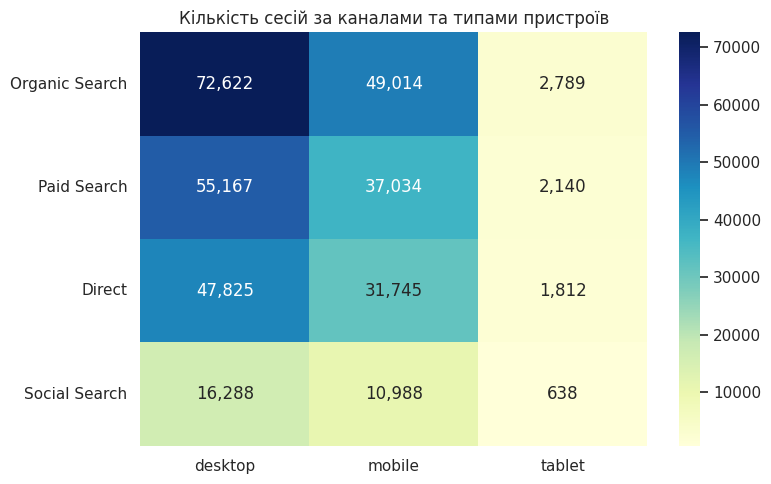

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(pivot_channel_device, annot=True, fmt=',d', cmap='YlGnBu', ax=ax)
ax.set_title('Кількість сесій за каналами та типами пристроїв')
ax.set_xlabel('')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

**Висновок.**
- Найбільше сесій припадає на Organic Search, Paid Search і Direct, а desktop у всіх каналах дає найбільше сесій, далі mobile, і з великим відривом tablet.
- Розподіл пристроїв практично однаковий для всіх каналів: desktop становить 58.4-58.8% сесій каналу, mobile 39.0-39.4%, tablet 2.2-2.3%. Канали відрізняються обсягом трафіку, а не складом пристроїв.
- Формально незалежність каналу й пристрою перевіряємо в розділі про відмінності між групами.

## 6.2. Як розподілені продажі між топ-10 категоріями в топ-5 країнах?

**Питання.** Як розподілена виручка між топ-10 категоріями товарів у топ-5 країнах? Чи відрізняється середня ціна покупки однієї категорії в різних країнах?

**Як рахуємо.**
- Категорії (топ-10) і країни (топ-5) відібрано за загальною виручкою.
- Сума продажів: сума цін куплених товарів у категорії для кожної країни.
- Середня ціна покупки: середнє значення ціни товару в рядках із покупкою для кожної пари «категорія і країна».
- Результати показуємо тепловими картами: темніший колір означає більше значення.

In [ ]:
pivot_cat_country_mean = pd.pivot_table(
    df[(df['category'].isin(top_10_category.index.to_list()))&(df['country'].isin(top_5_country))],
    values='price',
    index='category',
    columns='country',
    aggfunc='mean',
    fill_value=0
)
pivot_cat_country_mean = pivot_cat_country_mean.loc[top_10_category.index.to_list(), top_5_country]

In [ ]:
pivot_cat_country_sum = pd.pivot_table(
    df[(df['category'].isin(top_10_category.index.to_list()))&(df['country'].isin(top_5_country))],
    values='price',
    index='category',
    columns='country',
    aggfunc='sum',
    fill_value=0
)
pivot_cat_country_sum = pivot_cat_country_sum.loc[top_10_category.index.to_list(), top_5_country]

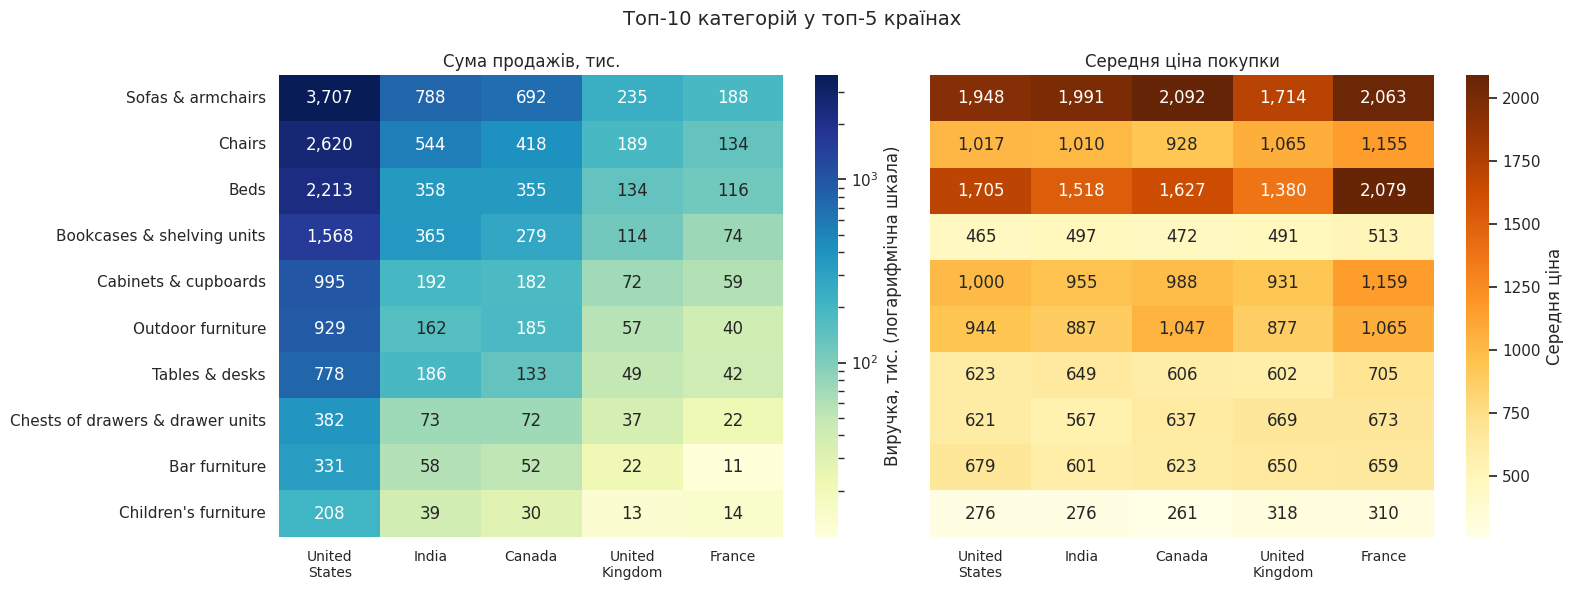

In [ ]:
from matplotlib.colors import LogNorm

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sum_k = pivot_cat_country_sum / 1000

# 1. Сума продажів
sns.heatmap(sum_k, annot=True, fmt=',.0f', cmap='YlGnBu',
            norm=LogNorm(vmin=sum_k.min().min(), vmax=sum_k.max().max()),
            cbar_kws={'label': 'Виручка, тис. (логарифмічна шкала)'}, ax=axes[0])
axes[0].set_title('Сума продажів, тис.')

# 2. Середня ціна покупки
sns.heatmap(pivot_cat_country_mean, annot=True, fmt=',.0f', cmap='YlOrBr',
            cbar_kws={'label': 'Середня ціна'}, ax=axes[1])
axes[1].set_title('Середня ціна покупки')

labels = [c.replace(' ', '\n') for c in top_5_country]
for ax in axes:
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.set_xticklabels(labels, rotation=0, fontsize=10)
axes[1].set_yticklabels([])
axes[1].tick_params(left=False)

fig.suptitle('Топ-10 категорій у топ-5 країнах', fontsize=14)
plt.tight_layout()
plt.show()

**Висновок.**
- Структура продажів за категоріями майже однакова в усіх топ-5 країнах: Sofas & armchairs, Chairs і Beds лідирують скрізь, а дитячі меблі й бар-меблі завершують список. Порядок категорій майже збігається, є лише дрібні перестановки сусідніх позицій (наприклад, в Індії Bookcases трохи випереджають Beds).
- США лідирують у кожній із десяти категорій. Для порівняння: у Sofas & armchairs виручка США становить ≈3.7 млн, тоді як у наступної країни (Індії) ≈0.8 млн. Кольори лівої карти подано на логарифмічній шкалі, щоб було видно відмінності між меншими країнами.
- Середня ціна покупки визначається категорією, а не країною: між категоріями вона відрізняється в рази (від ≈260-320 для дитячих меблів до ≈1 700-2 100 для диванів), а всередині однієї категорії між країнами здебільшого в межах приблизно чверті. Найбільший розкид у Beds (від ≈1 380 у Великій Британії до ≈2 080 у Франції), але для малих країн кількість покупок у таких клітинках невелика, тож середня ціна там нестійка.

**Бізнес-висновок.**
- Попит у кожній із топ-5 країн має ту саму структуру: три категорії (Sofas & armchairs, Chairs, Beds) формують основну частину виручки на всіх ринках, тож залежність від них системна, а не пов'язана з окремою країною.
- Країнової спеціалізації за категоріями за цими даними не виявлено, тому окремий асортимент під кожен ринок не підтверджується. Різниця між країнами це різниця в масштабі, а не в складі попиту.
- Різницю середніх цін між країнами формально не перевіряли, тому її варто розглядати як описове спостереження.

## 6.3. Як продажі розподілені між країнами та каналами?


**Питання.** Чи однакова структура каналів трафіку в топ-5 країнах за продажами і чи відрізняється розкид щоденних продажів між ними?

У 4.7 конверсія виявилась майже однаковою для всіх каналів і країн, тож різниця у виручці між ними мала б визначатись обсягом трафіку. Тут перевіряємо це глибше, на перетині двох ознак: чи зберігається така сама картина всередині комбінацій «країна і канал».

**Як рахуємо.**
- Продажі: сума цін куплених товарів у розрізі країни (топ-5 за продажами) і каналу трафіку. Канал «Undefined» виключаємо, як і в розділі 6.1. Для щоденних продажів використовуємо період без останніх 4 днів (88 днів).
- Розкид щоденних продажів оцінюємо за допомогою boxplot: він показує медіану, міжквартильний діапазон і викиди для кожної комбінації.

In [ ]:
# Зведена таблиця продажів в топ-5 країнах за каналами трафіку
pivot_channel_country = pd.pivot_table(
    df_with_sales[(df_with_sales['country'].isin(top_5_country))&(df_with_sales['traffic_channel']!='Undefined')],
    values='price',
    index='traffic_channel',
    columns='country',
    aggfunc='sum',
    fill_value=0
)
channels_no_undef = [c for c in channel_df.index if c != 'Undefined']
pivot_channel_country = pivot_channel_country.loc[channels_no_undef, top_5_country]
display(pivot_channel_country)
channel_share = (pivot_channel_country / pivot_channel_country.sum() * 100).round(1)
display(channel_share)

country,United States,India,Canada,United Kingdom,France
traffic_channel,,,,,
Organic Search,4958993.0,972575.7,873719.7,356438.9,261008.6
Paid Search,3589463.4,729970.0,674902.0,278652.6,192421.3
Direct,3346860.3,700256.0,609806.3,203728.9,169299.5
Social Search,1132651.1,215703.8,151244.2,51836.0,46713.4


country,United States,India,Canada,United Kingdom,France
traffic_channel,,,,,
Organic Search,38.1,37.1,37.8,40.0,39.0
Paid Search,27.6,27.9,29.2,31.3,28.7
Direct,25.7,26.7,26.4,22.9,25.3
Social Search,8.7,8.2,6.5,5.8,7.0


**Проміжний висновок.**
- Структура каналів трафіку за продажами схожа в усіх топ-5 країнах: Organic Search дає 37.1-40.0 % виручки країни, Paid Search 27.6-31.3%, Direct 22.9-26.7%, Social Search 5.8-8.7%, а порядок каналів скрізь однаковий.
- Невеликі відмінності є: у Великій Британії більша частка Organic і Paid та менша Direct і Social Search, а найбільшу частку Social Search має США (≈8.7% проти ≈5.8% у Великій Британії).
- США лідирують в кожному каналі, що узгоджується з їхньою часткою в загальних продажах (розділ 4.2).
- Результат підтверджує розділ 4.7: канали відрізняються обсягом, а не складом, і країни мають майже однакову структуру трафіку. Формально ця схожість не перевірялась, тому розцінюємо її як описову.

**Що розглядаємо далі.** Для побудови boxplot підготуємо довгоформатну таблицю щоденних продажів: для кожної комбінації «дата, країна, канал трафіку» рахуємо суму цін куплених товарів. Канал «Undefined» виключено.

In [ ]:
# Створення таблиці з продажами серед топ-5 країн в розрізі каналів трафіку за кожен день
df_date_channel_country =  df_with_sales[(df_with_sales['country'].isin(top_5_country))&(df_with_sales['traffic_channel']!='Undefined')]

# Створення довгоформатної таблиці продажів
date_channel_country = df_date_channel_country.groupby(
    ['date', 'country', 'traffic_channel'])['price'].sum().reset_index()
date_channel_country = date_channel_country

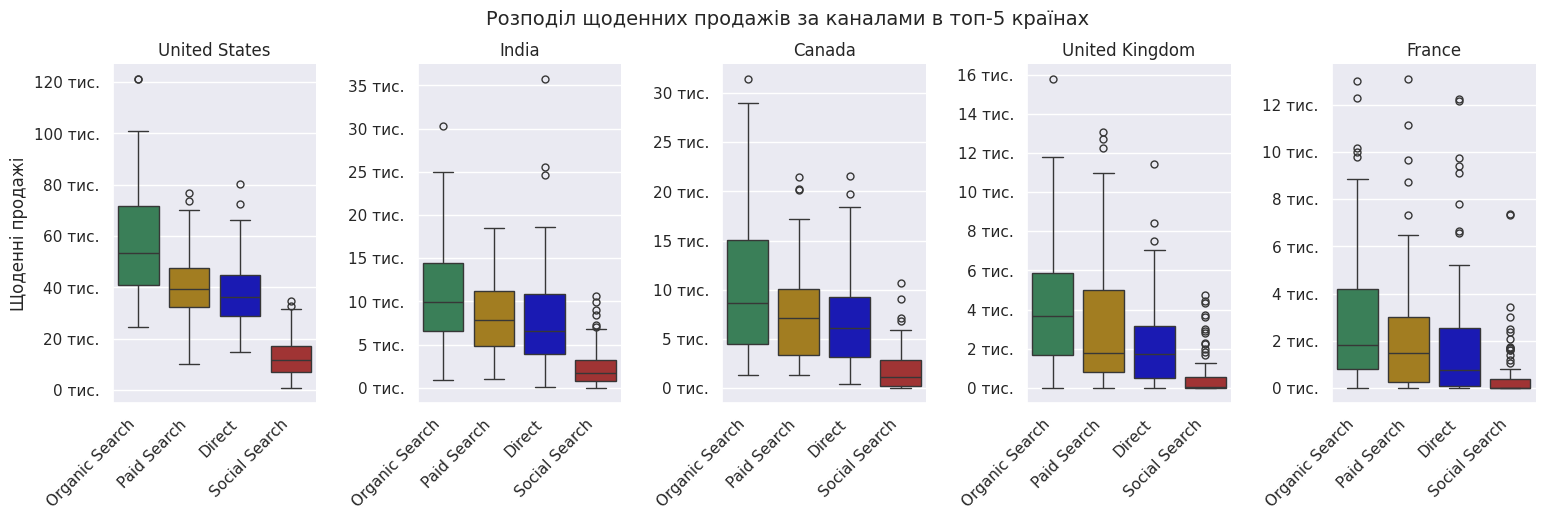

In [ ]:
palette_channel = {ch: colors_channel[ch]['rolling'] for ch in channels_no_undef}

x = sns.catplot(
    data=date_channel_country,
    kind='box',
    x='traffic_channel', y='price',
    col='country', col_order=top_5_country,
    order=channels_no_undef,
    hue='traffic_channel', hue_order=channels_no_undef,
    palette=palette_channel, legend=False,
    sharey=False,
    height=4.5, aspect=0.7
)

x.set_titles('{col_name}')
x.set_axis_labels('', 'Щоденні продажі')
for ax in x.axes.flat:
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x/1000:.0f} тис.'))
    ax.tick_params(axis='x', rotation=45)
    for label in ax.get_xticklabels():
        label.set_ha('right')

x.figure.suptitle('Розподіл щоденних продажів за каналами в топ-5 країнах', fontsize=14, y=1.03)
plt.show()

**Проміжний висновок.**
- У всіх топ-5 країнах канали мають однаковий порядок за рівнем щоденних продажів: Organic Search > Paid Search > Direct > Social Search. Найбільший розкид у Organic Search, найменший рівень у Social Search.
- Розподіл щоденних продажів скошений праворуч: у малих країнах (Велика Британія, Франція) більшість днів дає невеликі продажі, а викиди вгору можуть відповідати піковим дням.
- Осі Y на панелях різні, тому порівнюємо форму розподілу всередині країни, а не абсолютні рівні між країнами.

**Загальний висновок.**
- Структура каналів трафіку за продажами схожа в усіх топ-5 країнах: Organic Search дає 37.1-40.0% виручки країни, Paid Search 27.6-31.3%, Direct 22.9-26.7%, Social Search 5.8-8.7%, а порядок каналів однаковий скрізь.
- Така сама картина і за щоденними продажами: у кожній країні канали стоять в одному порядку за рівнем (Organic Search > Paid Search > Direct > Social Search), а найбільший розкид має Organic Search. Розподіл щоденних продажів скошений праворуч: у малих країнах більшість днів дає невеликі продажі, а викиди вгору можуть відповідати піковим дням.
- США лідирують у кожному каналі, що узгоджується з їхньою часткою в загальних продажах (розділ 4.2). Результат підтверджує розділ 4.7: канали відрізняються обсягом, а не складом, і країни мають майже однакову структуру трафіку.

**Бізнес-висновок.**
- Країни відрізняються масштабом продажів, а не структурою каналів, тому окремих канальних стратегій під кожен ринок за цими даними не потрібно: співвідношення каналів майже однакове скрізь.
- Основу продажів у кожній країні дають пошукові канали (Organic і Paid разом близько 65-70% виручки), а Social Search лишається найслабшим усюди.
- У малих ринках (Велика Британія, Франція) щоденні продажі нестабільніші відносно власного рівня: типовий день невеликий, а результат залежить від рідкісних пікових днів. Це гіпотеза за виглядом розподілів, формально її не перевіряли.

# 7. Статистичний аналіз взаємозв’язків

У цьому розділі перевіряємо, чи рухаються показники разом. Оскільки на рівні сесій числовою змістовною колонкою є лише ціна, одиницею аналізу стає день: для кожної дати рахуємо кілька числових показників і порівнюємо їх між собою.


## 7.1. Чи пов'язані кількість сесій і продажі?



**Питання.** Чи корелюють кількість сесій і загальні продажі за кожну дату? Наскільки сильний цей зв'язок і чи він статистично значущий?

**Як рахуємо.**
- Для кожної дати рахуємо кількість сесій і суму цін куплених товарів. Аналізуємо період із 01.11.2020 по 27.01.2021 (88 днів): останні 4 дні виключено, бо в них немає покупок при нормальному трафіку.
- Зв'язок спершу оцінюємо візуально за діаграмою розсіювання із лінією тренду.
- Вид коефіцієнта кореляції (Пірсона чи Спірмена) обираємо після перевірки розподілів обох показників: Пірсон потребує близького до нормального розподілу й відсутності сильних викидів, Спірмен до них нечутливий.
- Статистичну значущість оцінюємо за p-value, а також, дивимось на силу зв'язку.

In [ ]:
session_sales = df_with_sales.groupby('date').agg(
    sessions=('session_id', 'count'),
    sales=('price', 'sum'))

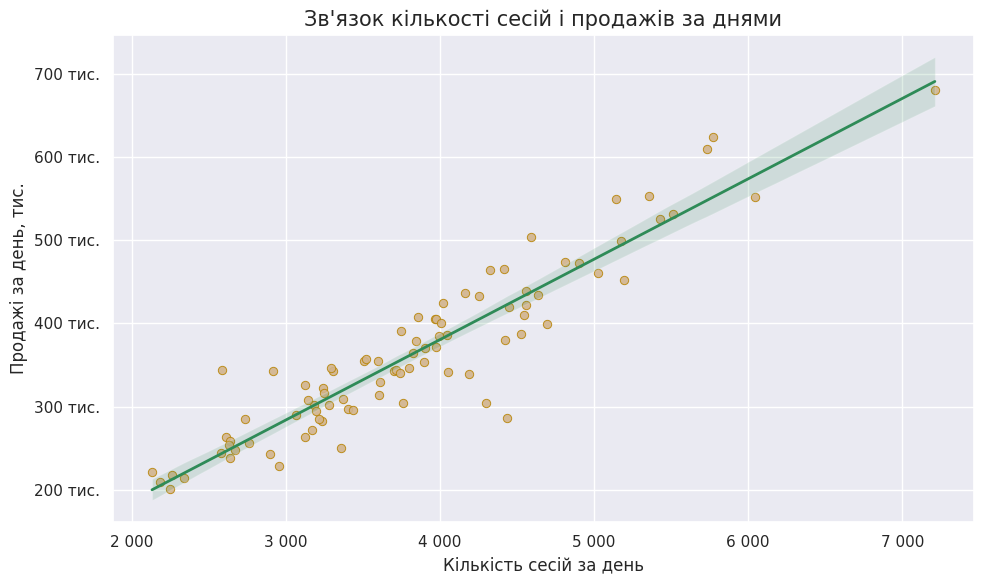

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.regplot(
    data=session_sales,
    x='sessions',
    y='sales',
    ax=ax,
    scatter_kws={'alpha': 0.9, 'color': 'tan', 'edgecolor': 'darkgoldenrod', 'linewidths': 0.7},
    line_kws={'color': 'seagreen', 'linewidth': 2},
    ci=95
)

ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:,.0f}'.replace(',', ' ')))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x/1000:.0f} тис.'))

ax.set_title('Зв\'язок кількості сесій і продажів за днями', fontsize=15)
ax.set_xlabel('Кількість сесій за день')
ax.set_ylabel('Продажі за день, тис.')

plt.tight_layout()
plt.show()

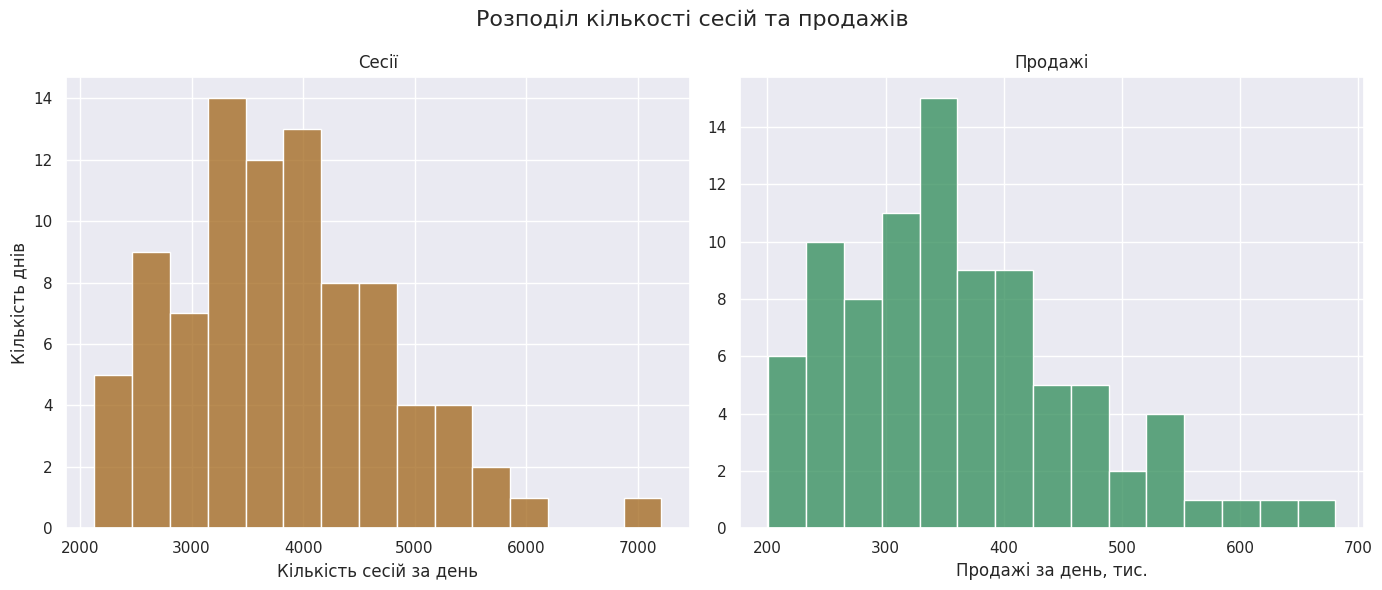

In [ ]:
sns.histplot(session_sales['sessions'], bins=15, ax=axes[0])

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.histplot(session_sales['sessions'], bins=15, ax=axes[0])
axes[0].set_title('Сесії')
axes[0].set_xlabel('Кількість сесій за день')
axes[0].set_ylabel('Кількість днів')

sns.histplot(session_sales['sales'], bins=15, ax=axes[1], color='seagreen')
axes[1].set_title('Продажі')
axes[1].set_xlabel('Продажі за день, тис.')
axes[1].set_ylabel('')
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x/1000:.0f}'))

fig.suptitle('Розподіл кількості сесій та продажів', fontsize=16)
plt.tight_layout()
plt.show()

In [ ]:
stat_s, p_sessions = stats.shapiro(session_sales['sessions'])
stat_p, p_sales = stats.shapiro(session_sales['sales'])

print(f'Сесії:  W = {stat_s:.3f}, p-value = {p_sessions:.4f}')
print(f'Продажі: W = {stat_p:.3f}, p-value = {p_sales:.4f}')

Сесії:  W = 0.970, p-value = 0.0395
Продажі: W = 0.956, p-value = 0.0048


In [ ]:
from scipy.stats import spearmanr

print(f"Test statistic and p-value: {spearmanr(session_sales['sessions'], session_sales['sales'])}")

spearman_corr = session_sales['sessions'].corr(
    session_sales['sales'], method="spearman")
print(f"Spearman Correlation: {spearman_corr}")

Test statistic and p-value: SignificanceResult(statistic=np.float64(0.904283047444613), pvalue=np.float64(1.5381769633064087e-33))
Spearman Correlation: 0.904283047444613


**Висновок.**
- **Діаграма розсіювання.** Зв'язок між кількістю сесій і продажами за день додатний, близький до лінійного й виглядає сильним. Один день (≈7 200 сесій) лежить окремо від решти.
- **Вибір коефіцієнта.** Гістограми обох показників скошені праворуч, а тест Шапіро-Вілка відхиляє нормальність для сесій (p = 0.040) і для продажів (p = 0.005). Тому основним методом обрано кореляцію Спірмена: вона працює з рангами, не вимагає нормального розподілу й нечутлива до викидів.
- **Результат.** Коефіцієнт Спірмена ρ = 0.90, p < 0.001: зв'язок сильний і статистично значущий. Дні з більшою кількістю сесій майже завжди мають і вищі продажі.
- **Інтерпретація.** Такий результат очікуваний: продажі за день це приблизно кількість сесій помножена на конверсію та середній чек, а в розділі 4.7 ми бачили, що конверсія майже стала. Отже, динаміку продажів задає насамперед обсяг трафіку, а не якість його конверсії.
- **Обмеження.** Кореляція показує, що показники рухаються разом, але не доводить причини.
- **Перехід до наступного підрозділу.** Динаміка продажів насамперед пов'язана з обсягом трафіку. У розділі «Аналіз динаміки продажів» лінії континентів, каналів трафіку й типів пристроїв рухались паралельно, але це було лише візуальне спостереження. Далі перевіряємо його кількісно: чи корелюють між собою щоденні продажі різних груп у межах кожного зрізу.

## 7.2. Чи рухаються продажі різних груп разом?


**Питання.** Чи корелюють між собою щоденні продажі різних континентів, каналів трафіку й типів пристроїв?

**Як рахуємо.**
- Одиниця аналізу ― день (88 днів), показник ― щоденні продажі кожної групи.
- Для всіх зрізів використовуємо кореляцію Спірмена: розподіли щоденних продажів скошені праворуч (як у 7.1), тож метод на рангах надійніший за Пірсона. Один і той самий метод у всіх трьох зрізах дозволяє порівнювати матриці між собою. Значущість оцінюємо за p-value (рівень 0.05) для кожної пари.
- Кореляційні матриці показуємо тепловими картами.
- Розглядаємо три зрізи: 7.2.1 континенти (топ-3), 7.2.2 канали трафіку, 7.2.3 типи пристроїв.

### 7.2.1. Кореляція щоденних продажів на топ-3 континентах

Найбільший p-value серед пар: 3.27e-10


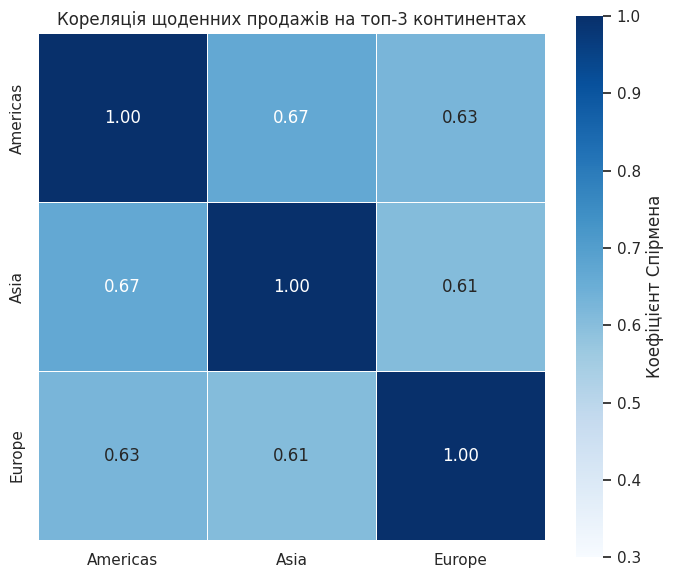

In [ ]:
# Так як в нас вже є таблиця щоденних продажів на топ-3 континентах, одразу переходимо до кореляції Спірмена
cols = top_3_cont   # ['Americas', 'Asia', 'Europe']

# Спірмен для всіх пар одразу: функція повертає дві матриці
res = stats.spearmanr(cont_daily_df[cols])
corr = pd.DataFrame(res.statistic, index=cols, columns=cols)   # коефіцієнти
pval = pd.DataFrame(res.pvalue, index=cols, columns=cols)      # p-value
print(f'Найбільший p-value серед пар: {pval.where(~np.eye(3, dtype=bool)).max().max():.2e}')

# Теплова карта кореляції
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='Blues',
            vmin=0.3, vmax=1, linewidths=0.5, square=True,
            cbar_kws={'label': 'Коефіцієнт Спірмена'}, ax=ax) # одразу задаємо vmin=0.3, бо очікуємо позитивну кореляцію
ax.set_title('Кореляція щоденних продажів на топ-3 континентах')
ax.set_xlabel('')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

**Висновок.** Щоденні продажі континентів корелюють (ρ = 0.61-0.67, p < 0.001): у дні високих продажів в одному регіоні вони зазвичай високі й в інших, тож регіони реагують на спільний чинник. Водночас зв'язок не жорсткий (близько 40% спільних коливань), тому в кожного континенту лишається власна мінливість.

### 7.2.2. Кореляція щоденних продажів серед 4 каналів трафіку (Undefined канал виключено)

Найбільший p-value серед пар: 2.14e-04


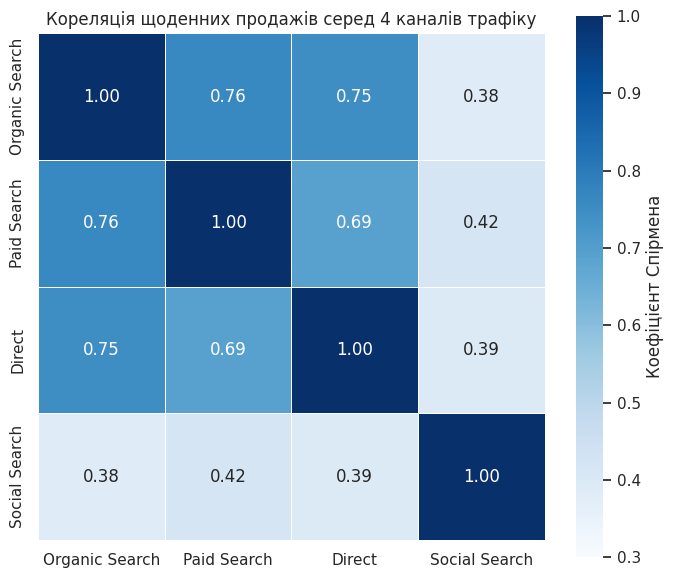

In [ ]:
cols = channels_no_undef

# Спірмен для всіх пар одразу: функція повертає дві матриці
res = stats.spearmanr(channel_daily_df[cols])
corr = pd.DataFrame(res.statistic, index=cols, columns=cols)   # коефіцієнти
pval = pd.DataFrame(res.pvalue, index=cols, columns=cols)      # p-value
print(f'Найбільший p-value серед пар: {pval.where(~np.eye(4, dtype=bool)).max().max():.2e}')

# Теплова карта кореляції
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='Blues',
            vmin=0.3, vmax=1, linewidths=0.5, square=True,
            cbar_kws={'label': 'Коефіцієнт Спірмена'}, ax=ax) # одразу задаємо vmin=0.3, бо очікуємо позитивну кореляцію
ax.set_title('Кореляція щоденних продажів серед 4 каналів трафіку')
ax.set_xlabel('')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

**Висновок.** Щоденні продажі трьох головних каналів (Organic Search, Paid Search, Direct) корелюють сильно (ρ = 0.69-0.76, p < 0.001), навіть сильніше, ніж продажі континентів: канали реагують на спільний чинник. Social Search зв'язаний з ними слабше (ρ = 0.38-0.42, p < 0.001), що узгоджується з розділом 5, де його лінія майже не мала грудневого підйому, Social Search мав малий рівень продажів, тож частка шуму вища: його щоденні продажі мають більшу частку власних коливань.

### 7.2.3. Кореляція щоденних продажів серед типів пристрою

Найбільший p-value серед пар: 1.71e-04


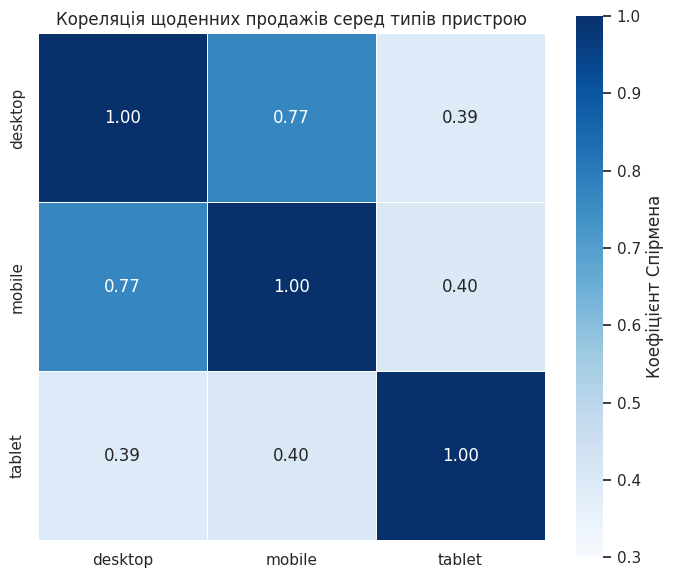

In [ ]:
cols = device_order

# Спірмен для всіх пар одразу: функція повертає дві матриці
res = stats.spearmanr(device_daily_df[cols])
corr = pd.DataFrame(res.statistic, index=cols, columns=cols)   # коефіцієнти
pval = pd.DataFrame(res.pvalue, index=cols, columns=cols)      # p-value
print(f'Найбільший p-value серед пар: {pval.where(~np.eye(3, dtype=bool)).max().max():.2e}')

# Теплова карта кореляції
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='Blues',
            vmin=0.3, vmax=1, linewidths=0.5, square=True,
            cbar_kws={'label': 'Коефіцієнт Спірмена'}, ax=ax) # одразу задаємо vmin=0.3, бо очікуємо позитивну кореляцію
ax.set_title('Кореляція щоденних продажів серед типів пристрою')
ax.set_xlabel('')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

**Висновок.** Щоденні продажі desktop і mobile корелюють сильно (ρ = 0.77, p < 0.001): це один із найсильніших зв'язків у розділі. Tablet зв'язаний із ними слабше (ρ = 0.39-0.40, p < 0.001). Імовірне пояснення: на малому рівні продажів (близько 2% виручки) щоденні коливання складаються здебільшого з випадкового шуму; це гіпотеза, яку дані не підтверджують.

## 7.3. Чи взаємопов'язані продажі серед топ-5 категорій товарів?

**Питання.** Чи корелюють між собою щоденні продажі серед топ-5 категорій товарів?

**Як рахуємо.**
- Одиниця аналізу ― день (88 днів), показник ― щоденні продажі серед топ-5 категорій товарів.
- Використовуємо кореляцію Спірмена: розподіл щоденних продажів скошені праворуч (як у 7.1), тож метод на рангах надійніший за Пірсона. Значущість оцінюємо за p-value (рівень 0.05) для кожної пари.
- Кореляційну матрицю показуємо тепловою картою.

Найбільший p-value серед пар: 1.76e-05


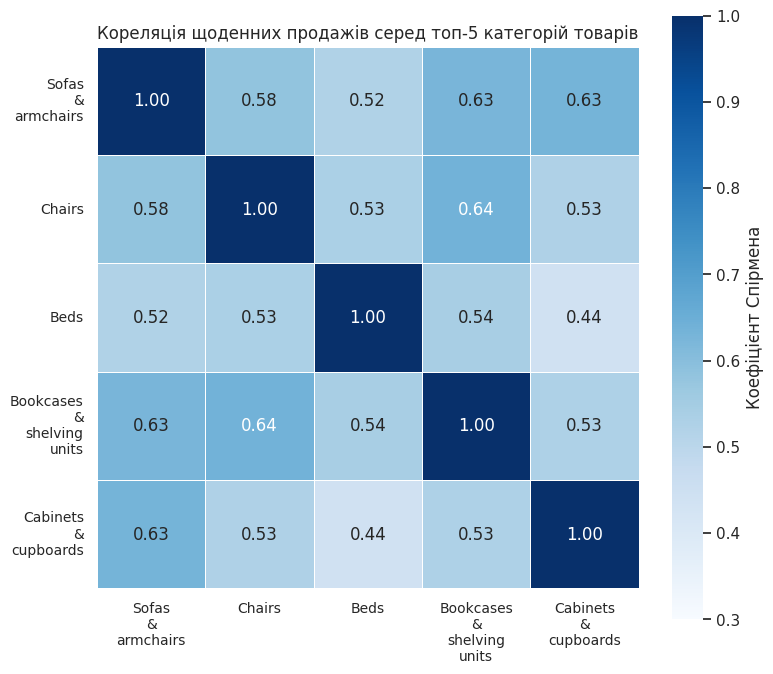

In [ ]:
# Створюємо таблицю щоденних продажів для топ-5 категорій
top_5_category = ['Sofas & armchairs', 'Chairs', 'Beds', 'Bookcases & shelving units', 'Cabinets & cupboards']
category_5_daily_df = pd.pivot_table(
    df_with_sales[df_with_sales['category'].isin(top_5_category)],
    values='price',
    index='date',
    columns='category',
    aggfunc='sum',
    fill_value=0)

cols = top_5_category
# Спірмен для всіх пар одразу: функція повертає дві матриці
res = stats.spearmanr(category_5_daily_df[cols])
corr = pd.DataFrame(res.statistic, index=cols, columns=cols)   # коефіцієнти
pval = pd.DataFrame(res.pvalue, index=cols, columns=cols)      # p-value
print(f'Найбільший p-value серед пар: {pval.where(~np.eye(5, dtype=bool)).max().max():.2e}')

# Теплова карта кореляції
fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='Blues',
            vmin=0.3, vmax=1, linewidths=0.5, square=True,
            cbar_kws={'label': 'Коефіцієнт Спірмена'}, ax=ax) # одразу задаємо vmin=0.3, бо очікуємо позитивну кореляцію

wrapped = [c.replace(' & ', ' &\n').replace(' ', '\n') if len(c) > 14 else c for c in cols]
ax.set_xticklabels(wrapped, rotation=0, fontsize=10)
ax.set_yticklabels(wrapped, rotation=0, fontsize=10)
ax.set_title('Кореляція щоденних продажів серед топ-5 категорій товарів')
ax.set_xlabel('')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

**Висновок.** Щоденні продажі топ-5 категорій корелюють між собою додатно й значущо (ρ = 0.44-0.64, усі p < 0.001): у дні високих продажів в одній категорії вони зазвичай високі й в інших. Найсильніші зв'язки в Chairs і Bookcases (0.64), а також Sofas з Bookcases і Cabinets (0.63), найслабший у Beds і Cabinets (0.44). Зв'язки слабші, ніж між каналами чи пристроями, імовірно, бо окремі категорії менші й їхні щоденні продажі містять більше випадкового шуму. Це гіпотеза, яку дані не підтверджують.

## 7.4. Чи залежить конверсія від обсягу трафіку?



**Питання.** Чи корелює щоденна кількість сесій із щоденною конверсією сесій у покупку? Чи змінюється якість трафіку, коли його стає більше?

**Чому це цікаво.**
- У 7.1 з'ясували, що щоденні продажі сильно залежать від кількості сесій (ρ = 0.90), а в розділі 4.7 конверсія була майже однаковою в усіх каналах, пристроях і країнах. Але це були порівняння між групами. Тут перевіряємо інше: чи сама конверсія змінюється **з обсягом трафіку** від дня до дня.
- Відповідь має практичний сенс. Якщо конверсія не залежить від трафіку, то зростання кількості сесій переходить у зростання продажів приблизно пропорційно. Якщо вона знижується в дні піків, додатковий трафік менш цінний (приходять менш мотивовані відвідувачі). Якщо підвищується, пікові дні привабливіші для покупців.

**Як рахуємо.**
- Для кожної дати рахуємо кількість сесій, кількість покупок і конверсію (покупки ÷ сесії). Період 01.11.2020-27.01.2021 (88 днів).
- Зв'язок оцінюємо діаграмою розсіювання (одна точка це один день) і кореляцією Спірмена з p-value (рівень 0.05). Метод той самий, що в попередніх підрозділах, адже щоденні показники мають скошені розподіли.
- Конверсія містить сесії у знаменнику, тому навіть без реального зв'язку між трафіком і поведінкою покупців може виникнути слабкий від'ємний зв'язок суто через спосіб обчислення. Тому результат інтерпретуємо обережно, а кореляцію не вважаємо доказом причини.

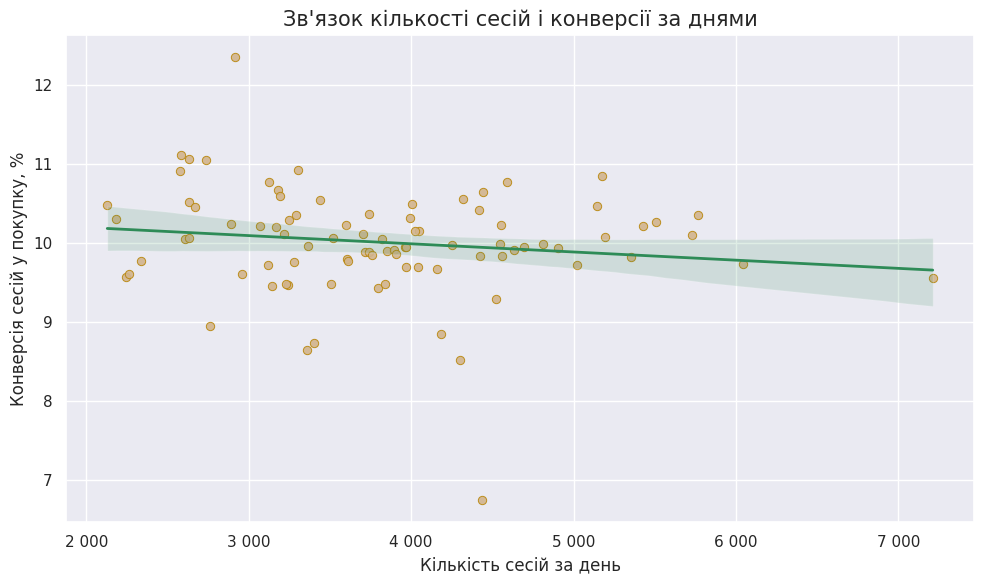

In [ ]:
# Створення таблиці з кількістю сесій, кількістю покупок та конверсією сесій в покупку
df_session_sales_cr = df_with_sales.groupby('date').agg(
    session_cnt=('session_id', 'count'),
    sales_cnt=('price', 'count')
).reset_index()

df_session_sales_cr['conversion_rate_%'] = (
    df_session_sales_cr['sales_cnt'] / df_session_sales_cr['session_cnt'] * 100
).astype('float64')

# Діаграма розсіювання
fig, ax = plt.subplots(figsize=(10, 6))
sns.regplot(
    data=df_session_sales_cr,
    x='session_cnt',
    y='conversion_rate_%',
    ax=ax,
    scatter_kws={'alpha': 0.9, 'color': 'tan', 'edgecolor': 'darkgoldenrod', 'linewidths': 0.7},
    line_kws={'color': 'seagreen', 'linewidth': 2},
    ci=95
)

ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:,.0f}'.replace(',', ' ')))
ax.set_title('Зв\'язок кількості сесій і конверсії за днями', fontsize=15)
ax.set_xlabel('Кількість сесій за день')
ax.set_ylabel('Конверсія сесій у покупку, %')
plt.tight_layout()
plt.show()

In [ ]:
rho, p_value = stats.spearmanr(
    df_session_sales_cr['session_cnt'],
    df_session_sales_cr['conversion_rate_%']
)
print(f'Коефіцієнт Спірмена: ρ = {rho:.3f}, p-value = {p_value:.4f}')

Коефіцієнт Спірмена: ρ = -0.130, p-value = 0.2259


**Висновок.** Конверсія сесій у покупку не залежить помітно від обсягу трафіку: коефіцієнт Спірмена ρ = -0.13, p = 0.23, тобто значущого зв'язку виявити не вдалося. Слабкий від'ємний нахил лінії тренду статистично не підтверджується. Разом із результатом 7.1 це означає, що зростання кількості сесій переходить у зростання продажів приблизно пропорційно: у дні піків трафік не стає ні менш, ні більш цінним.

**Загальний висновок до розділу.**
- Щоденні продажі сильно пов'язані з кількістю сесій (ρ = 0.90, p < 0.001), тоді як конверсія від обсягу трафіку не залежить (ρ = -0.13, p = 0.23). Отже, зростання трафіку переходить у зростання продажів приблизно пропорційно.
- Продажі різних континентів, каналів трафіку, типів пристроїв і категорій рухаються разом: усі зв'язки додатні й значущі (p < 0.001). Найсильніші вони між великими групами (desktop і mobile ρ = 0.77, головні канали 0.69-0.76), слабші для малих (Social Search ≈0.4, tablet ≈0.4). Імовірне пояснення: у малих групах щоденні значення складаються здебільшого з випадкового шуму, це гіпотеза, яку дані не підтверджують.
- Для всіх зрізів використано кореляцію Спірмена, бо розподіли щоденних продажів скошені праворуч (тест Шапіро-Вілка відхиляє нормальність).

**Бізнес-висновок.**
- Головний важіль продажів - обсяг трафіку: його якість (конверсія) від дня до дня практично не змінюється, тож керувати результатом доцільно через кількість сесій.
- Континенти, канали й пристрої реагують на спільні чинники, тому диверсифікація між ними дає лише часткове згладжування ризику: в поганий день продажі просідають одразу в більшості груп.
- Причини спільного руху дані не пояснюють.

# 8. Статистичний аналіз відмінностей між групами


У розділі 7 ми з'ясували, що показники рухаються разом. Кореляція, однак, не відповідає на інше питання: чи відрізняються групи між собою за рівнем. Дві групи можуть мати однакову динаміку, але різний масштаб, і навпаки.



## 8.1. Чи відрізняються щоденні продажі зареєстрованих і незареєстрованих користувачів?



**Питання.** Чи відрізняються щоденні продажі зареєстрованих користувачів від продажів незареєстрованих?

**Як рахуємо.**
- Зареєстрованими вважаємо сесії із заповненим `account_id`, решту незареєстрованими. Для кожної дати рахуємо суму цін куплених товарів в обох групах. Період 01.11.2020-27.01.2021 (88 днів).
- Групи сильно відрізняються за розміром (зареєстровані дають близько 8% сесій), тому суми продажів відображають насамперед розмір групи. Для чесного порівняння рахуємо ще й виручку на одну сесію: щоденні продажі групи, поділені на кількість сесій цієї групи за той самий день.
- Дві вибірки складаються з тих самих 88 днів, тому вони парні, а не незалежні.
- Спершу порівнюємо розподіли обох показників (гістограми, тест Шапіро-Вілка), і за їхньою формою обираємо тест. Значущість оцінюємо за p-value (рівень 0.05) разом із розміром різниці.

In [ ]:
user_type = np.where(df_with_sales['account_id'].notna(), 'registered', 'unregistered')

# Сесії й продажі за кожною датою для кожної групи
reg_daily = (
    df_with_sales.assign(user_type=user_type)
    .groupby(['date', 'user_type'])
    .agg(sessions=('session_id', 'count'), sales=('price', 'sum'))
    .reset_index()
)
reg_daily['sales_per_session'] = reg_daily['sales'] / reg_daily['sessions']

# Зведені таблиці
sales_wide = reg_daily.pivot(index='date', columns='user_type', values='sales').astype('float64')
sps_wide = reg_daily.pivot(index='date', columns='user_type', values='sales_per_session').astype('float64')

# Перевірки
print('Днів без продажів:\n', (sales_wide == 0).sum())
print('Частка зареєстрованих у сесіях:',
      round(reg_daily.loc[reg_daily['user_type'] == 'registered', 'sessions'].sum() / reg_daily['sessions'].sum() * 100, 1), '%')

Днів без продажів:
 user_type
registered      0
unregistered    0
dtype: int64
Частка зареєстрованих у сесіях: 8.3 %


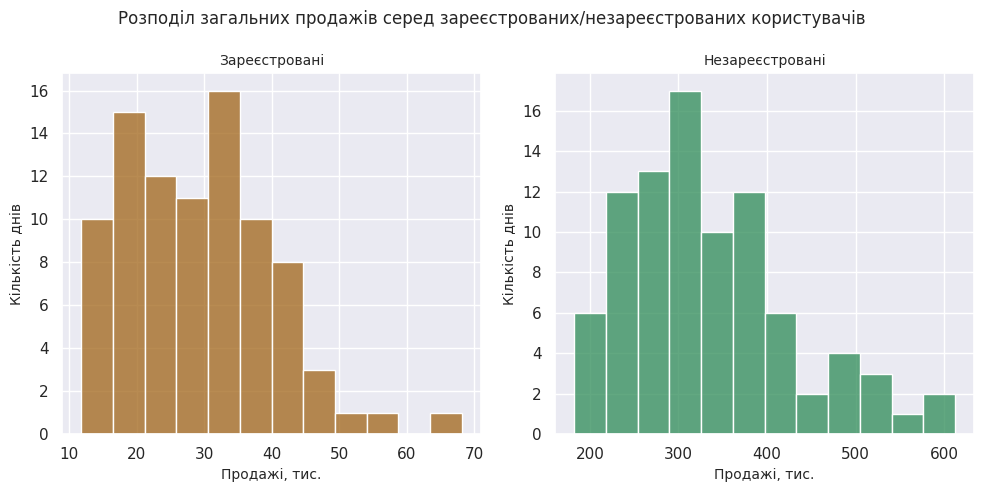

In [ ]:
# Розподіл загальних продажів
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

sns.histplot(sales_wide['registered'], bins=12, ax=axes[0])
axes[0].set_title('Зареєстровані', fontsize=10)
axes[0].set_xlabel('Продажі, тис.', fontsize=10)
axes[0].set_ylabel('Кількість днів', fontsize=10)
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x/1e3:.0f}'))

sns.histplot(sales_wide['unregistered'], bins=12, color='seagreen', ax=axes[1])
axes[1].set_title('Незареєстровані', fontsize=10)
axes[1].set_xlabel('Продажі, тис.', fontsize=10)
axes[1].set_ylabel('Кількість днів', fontsize=10)
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x/1e3:.0f}'))

fig.suptitle('Розподіл загальних продажів серед зареєстрованих/незареєстрованих користувачів', fontsize=12)
plt.tight_layout()
plt.show()

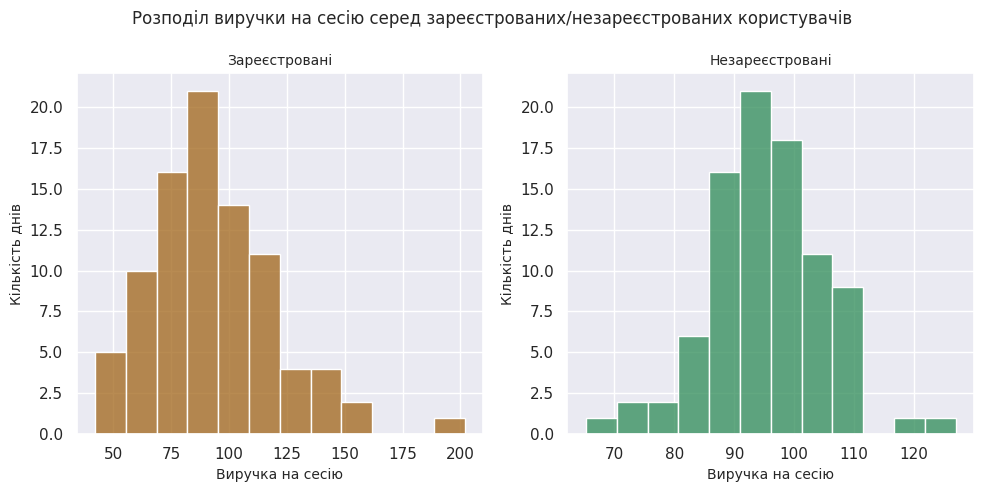

In [ ]:
# Розподіл середніх продажів (виручка на сесію)
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

sns.histplot(sps_wide['registered'], bins=12, ax=axes[0])
axes[0].set_title('Зареєстровані', fontsize=10)
axes[0].set_xlabel('Виручка на сесію', fontsize=10)
axes[0].set_ylabel('Кількість днів', fontsize=10)
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0f}'))

sns.histplot(sps_wide['unregistered'], bins=12, color='seagreen', ax=axes[1])
axes[1].set_title('Незареєстровані', fontsize=10)
axes[1].set_xlabel('Виручка на сесію', fontsize=10)
axes[1].set_ylabel('Кількість днів', fontsize=10)
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0f}'))

fig.suptitle('Розподіл виручки на сесію серед зареєстрованих/незареєстрованих користувачів', fontsize=12)
plt.tight_layout()
plt.show()

**Вибір тесту.** Порівнюємо дві групи за одні й ті самі 88 днів, тож для кожного дня маємо пару значень. Вибір тесту залежить від того, чи розподіл щоденних різниць між групами близький до нормального: якщо так, підходить парний t-тест, якщо ні, тест Вілкоксона. Це перевіряємо тестом Шапіро-Вілка. Порівнюємо виручку на сесію, бо загальні суми залежать від розміру груп.

Зареєстровані: W = 0.953, p-value = 0.0028
Незареєстровані: W = 0.981, p-value = 0.2397
Різниця (парна): W = 0.977, p-value = 0.1140


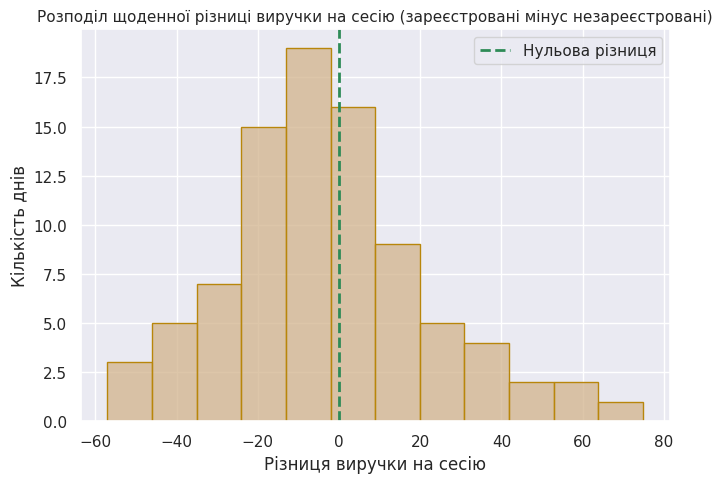

In [ ]:
# Різниця виручки на сесію за кожен день (зареєстровані мінус незареєстровані)
diff_sps = sps_wide['registered'] - sps_wide['unregistered']

# Тест Шапіро-Вілка: обидві групи й різниця
for name, series in [('Зареєстровані', sps_wide['registered']),
                     ('Незареєстровані', sps_wide['unregistered']),
                     ('Різниця (парна)', diff_sps)]:
    W, p = stats.shapiro(series)
    print(f'{name}: W = {W:.3f}, p-value = {p:.4f}')

# 3. Гістограма різниць
fig, ax = plt.subplots(figsize=(7, 5))
sns.histplot(diff_sps, bins=12, color='tan', edgecolor='darkgoldenrod', ax=ax)
ax.axvline(0, color='seagreen', linestyle='--', linewidth=2, label='Нульова різниця')
ax.set_title('Розподіл щоденної різниці виручки на сесію (зареєстровані мінус незареєстровані)', fontsize=11)
ax.set_xlabel('Різниця виручки на сесію')
ax.set_ylabel('Кількість днів')
ax.legend()
plt.tight_layout()
plt.show()

**Результат перевірки на нормальність.** Тест Шапіро-Вілка показав, що розподіл щоденних різниць виручки на сесію між групами близький до нормального (p = 0.114 > 0.05). У зареєстрованих окремо розподіл дещо скошений через один день з високою виручкою (p = 0.003), але для парного тесту важливі саме різниці. Тому обираємо парний t-тест.

In [ ]:
from scipy.stats import ttest_rel

t_stat, p_value = ttest_rel(sps_wide['registered'], sps_wide['unregistered'])
print(f"t-statistic: {t_stat}, p-value: {p_value}")

t-statistic: -0.9674984453830074, p-value: 0.33597681991038897


**Результат.** Парний t-тест не виявив значущої різниці у виручці на сесію між зареєстрованими та незареєстрованими користувачами (t = -0.97, p = 0.34). Отже, у розрахунку на сесію зареєстровані купують приблизно так само, як і незареєстровані. Загальні продажі зареєстрованих значно менші (≈30 тис. на день проти ≈320 тис.), але це пояснюється розміром групи: вона дає лише близько 8% сесій. Сесії зареєстрованих це фактично сесії реєстрації, тому результат не описує повної поведінки зареєстрованих клієнтів.

**Висновок.**
- Загальні щоденні продажі зареєстрованих значно менші, ніж незареєстрованих, але це зумовлено розміром групи: вона дає лише близько 8% сесій.
- У розрахунку на сесію різниці немає: парний t-тест не виявив значущої відмінності (p = 0.34). Зареєстровані купують приблизно так само, як і незареєстровані.
- Сесії зареєстрованих це фактично сесії реєстрації (кожен акаунт має в даних одну сесію), тому результат стосується моменту реєстрації, а не повної поведінки зареєстрованих клієнтів.

**Бізнес-висновок.** Сама реєстрація за цими даними не робить сесію цінішою: виручка на сесію в обох груп однакова. Тож цінність реєстрованої бази, якщо вона є, лежить поза межами однієї сесії (наприклад, у повторних покупках чи розсилці), і ці дані її оцінити не дозволяють.

## 8.2. Чи відрізняється кількість сесій між каналами трафіку?


**Питання.** Чи статистично значущо відрізняється щоденна кількість сесій між каналами трафіку, і які саме канали відрізняються між собою?

**Як рахуємо.**
- Для кожної дати рахуємо кількість сесій окремо для кожного каналу. Аналізуємо весь період, 01.11.2020-31.01.2021 (92 дні): на відміну від аналізу продажів, останні 4 дні тут не виключаємо, бо сесії в них фіксувалися в звичайному обсязі. Канал «Undefined» виключаємо, як і в попередніх розділах.
- Канали порівнюємо на тих самих днях, тому групи не є незалежними: кожен день дає по одному значенню для кожного каналу. Для такого випадку підходить тест Фрідмана (працює з рангами, не вимагає нормальності). Нульова гіпотеза: щоденна кількість сесій однакова в усіх каналах.
- Якщо відмінності значущі, порівнюємо канали попарно тестом Вілкоксона з поправкою Бонферроні на кількість пар (6).
- Розмір ефекту оцінюємо коефіцієнтом узгодженості Кендалла W: значущість сама по собі не показує, наскільки відмінності великі.

In [ ]:
channel_sessions_df = pd.pivot_table(
    df[df['traffic_channel']!='Undefined'],
    values='session_id',
    index='date',
    columns='traffic_channel',
    aggfunc='count',
    fill_value=0
).astype('int64')

channel_sessions_long = channel_sessions_df.melt(
    var_name='traffic_channel', value_name='sessions')

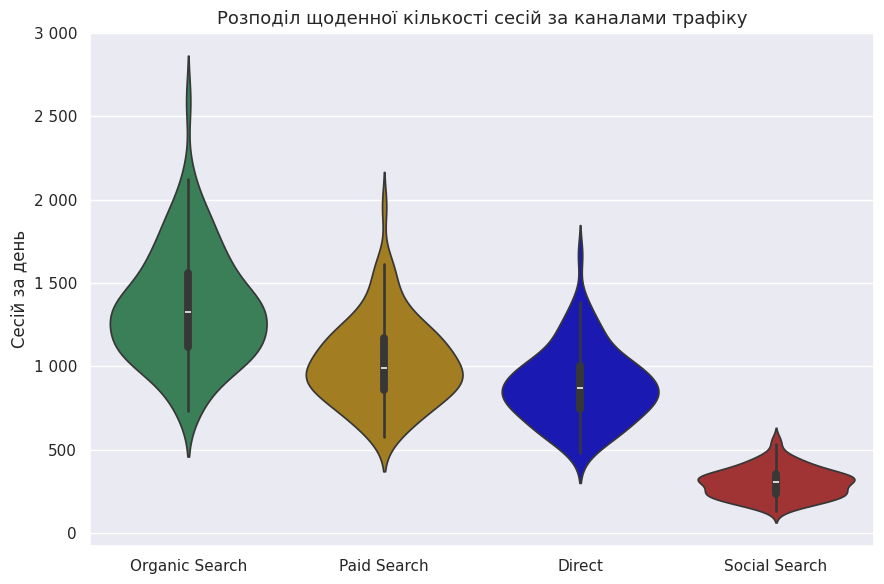

In [ ]:
palette_channel = {ch: colors_channel[ch]['rolling'] for ch in channels_no_undef}

fig, ax = plt.subplots(figsize=(9, 6))
sns.violinplot(
    data=channel_sessions_long,
    x='traffic_channel', y='sessions',
    hue='traffic_channel',
    order=channels_no_undef, hue_order=channels_no_undef,
    palette=palette_channel, legend=False,
    inner='box', ax=ax)

ax.set_title('Розподіл щоденної кількості сесій за каналами трафіку', fontsize=13)
ax.set_xlabel('')
ax.set_ylabel('Сесій за день')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:,.0f}'.replace(',', ' ')))
plt.tight_layout()
plt.show()

**Огляд розподілів.** Щоденна кількість сесій має чіткий порядок за рівнем: Organic Search (медіана ≈1 330) > Paid Search (≈990) > Direct (≈870) > Social Search (≈310). Social Search лежить окремо від решти, тоді як розподіли трьох головних каналів частково перекриваються, особливо Paid Search і Direct. У всіх розподілів довгий верхній хвіст (дні піків), тому далі використовуємо непараметричний тест.

In [ ]:
data = channel_sessions_df[channels_no_undef].astype('int64')   # 92 дні × 4 канали
n, k = data.shape

# Тест Фрідмана: чи однакова щоденна кількість сесій у всіх каналах
chi2, p = stats.friedmanchisquare(*[data[c] for c in data.columns])
kendall_w = chi2 / (n * (k - 1))
print(f'Фрідман: chi2 = {chi2:.1f}, p-value = {p:.2e}')
print(f'Kendall W = {kendall_w:.2f}')

# Середній ранг каналу всередині дня (1 = найменше сесій, 4 = найбільше)
print('\nСередній ранг за день:')
print(data.rank(axis=1).mean().sort_values(ascending=False).round(2))


Фрідман: chi2 = 276.0, p-value = 1.55e-59
Kendall W = 1.00

Середній ранг за день:
traffic_channel
Organic Search    4.0
Paid Search       3.0
Direct            2.0
Social Search     1.0
dtype: float64


In [ ]:
# Парні порівняння: Вілкоксон з поправкою Бонферроні
from itertools import combinations
rows = []
pairs = list(combinations(data.columns, 2))
for a, b in pairs:
    stat, p_pair = stats.wilcoxon(data[a], data[b])
    rows.append({
        'Пара': f'{a} і {b}',
        'Медіана різниці': (data[a] - data[b]).median(),
        'p-value': p_pair,
        'p з поправкою': min(p_pair * len(pairs), 1.0),
    })
pairwise = pd.DataFrame(rows)
pairwise['Значуща'] = pairwise['p з поправкою'] < 0.05
display(pairwise.round(4))

,Пара,Медіана різниці,p-value,p з поправкою,Значуща
0,Organic Search і Paid Search,316.0,0.0,0.0,True
1,Organic Search і Direct,435.0,0.0,0.0,True
2,Organic Search і Social Search,1020.0,0.0,0.0,True
3,Paid Search і Direct,138.5,0.0,0.0,True
4,Paid Search і Social Search,695.0,0.0,0.0,True
5,Direct і Social Search,563.0,0.0,0.0,True


In [ ]:
(data.rank(axis=1) == [4, 3, 2, 1]).all().all()

np.True_

**Висновок.**
- Щоденна кількість сесій значуще відрізняється між каналами (тест Фрідмана, p < 0.001). Коефіцієнт узгодженості Кендалла W = 1.00: у кожен із 92 днів канали розташовані в одному й тому самому порядку, Organic Search > Paid Search > Direct > Social Search.
- Усі шість парних порівнянь значущі (Вілкоксон із поправкою Бонферроні, p < 0.001). Найбільша різниця між Organic Search і Social Search (медіана ≈1 020 сесій на день), найменша між Paid Search і Direct (≈140).
- Отже, піки й провали трафіку зачіпають усі канали одночасно, а їхнє співвідношення за обсягом лишається сталим.

**Бізнес-висновок.** Структура трафіку за каналами стабільна: у жодний день порядок за обсягом не змінився. Це узгоджується з розділом 7, де канали рухались разом. Причини такого порядку дані не пояснюють.

## 8.3. Чи відрізняється доля сесій з органічним трафіком у Європі та Америці?

**Питання.** Чи статистично значущо відрізняється частка сесій з органічним трафіком (Organic Search) серед усіх сесій у Європі та в Америці?

**Як рахуємо.**
- Для кожного з двох континентів рахуємо загальну кількість сесій і кількість сесій з каналом Organic Search за весь період (01.11.2020-31.01.2021, 92 дні: це аналіз трафіку, тому останні 4 дні не виключаємо). Канал «Undefined» виключаємо, тож частка розраховується від сесій з відомим каналом.
- Порівнюємо дві частки тестом двох пропорцій: нульова гіпотеза, що частка органічних сесій однакова в Європі й Америці; рівень значущості 0.05.
- Вибірки великі (десятки тисяч сесій), тому навіть невелика різниця може вийти значущою. Тому окрім p-value оцінюємо розмір різниці: різницю часток у відсоткових пунктах і довірчий інтервал для неї.

In [ ]:
cont_EU_AM = ['Americas', 'Europe']
channel_cont_df = pd.pivot_table(
    df[(df['traffic_channel'] != 'Undefined') & (df['continent'].isin(cont_EU_AM))],
    values='session_id',
    index='continent',
    columns='traffic_channel',
    aggfunc='count',
    fill_value=0
).astype('int64')

channel_cont_df['total'] = channel_cont_df[channels_no_undef].sum(axis=1)
channel_cont_df['organic_%'] = (channel_cont_df['Organic Search'] / channel_cont_df['total'] * 100).round(2)
channel_cont_df

traffic_channel,Direct,Organic Search,Paid Search,Social Search,total,organic_%
continent,,,,,,
Americas,44982,68671,52188,15372,181213,37.90
Europe,15163,23195,17561,5249,61168,37.92


In [ ]:
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep

count = channel_cont_df['Organic Search'].values   # органічні сесії: [Americas, Europe]
nobs = channel_cont_df['total'].values             # усі сесії: [Americas, Europe]

z_stat, p_value = proportions_ztest(count, nobs)
print(f'z = {z_stat:.3f}, p-value = {p_value:.3f}')

# Розмір різниці: частка Америки мінус частка Європи
diff = (count[0] / nobs[0] - count[1] / nobs[1]) * 100
low, high = confint_proportions_2indep(count[0], nobs[0], count[1], nobs[1])
print(f'Різниця: {diff:.2f} п.п., 95% ДІ: [{low*100:.2f}; {high*100:.2f}] п.п.')

if p_value < 0.05:
    print('Різниця часток статистично значуща.')
else:
    print('Значущої різниці часток виявити не вдалося.')

z = -0.110, p-value = 0.912
Різниця: -0.02 п.п., 95% ДІ: [-0.47; 0.42] п.п.
Значущої різниці часток виявити не вдалося.


**Результат.** Частка органічних сесій майже однакова: 37.90% в Америці та 37.92% в Європі. Тест двох пропорцій не виявив значущої різниці (z = -0.11, p = 0.91); різниця становить -0.02 п.п., 95% довірчий інтервал [-0.47; 0.42] п.п. охоплює нуль.

**Висновок.** Частка органічного трафіку в Європі та Америці статистично не відрізняється. Вибірки великі, тому довірчий інтервал вузький: якщо різниця й існує, вона не перевищує приблизно пів відсоткового пункту. Це узгоджується з розділом 6.3, де структура каналів була схожою в усіх країнах: географія майже не впливає на склад каналів.

**Бізнес-висновок.** Склад каналів трафіку в Америці та Європі практично однаковий, тому окремі канальні стратегії під кожен із цих ринків за цими даними не потрібні. Причин такої однаковості дані не пояснюють.

## 8.4. Чи залежить розподіл типів пристроїв від каналу трафіку?



**Питання.** Чи однаковий розподіл сесій за типами пристроїв (desktop, mobile, tablet) у різних каналах трафіку, чи канал і пристрій пов'язані між собою?

**Зв'язок із розділом 6.1.** У 6.1 частки пристроїв усередині каналів виглядали майже однаковими (desktop ≈58-59%, mobile ≈39%, tablet ≈2%), але це було візуальне спостереження. Тут перевіряємо його формально.

**Як рахуємо.**
- Беремо таблицю кількості сесій за каналами й типами пристроїв із розділу 6.1 (весь період, 92 дні; канал «Undefined» виключено).
- Застосовуємо тест хі-квадрат на незалежність. Нульова гіпотеза: розподіл пристроїв не залежить від каналу. Рівень значущості 0.05.
- Вибірка велика (понад 300 тисяч сесій), тому навіть дрібна різниця може вийти значущою. Тому окрім p-value оцінюємо силу зв'язку за коефіцієнтом Крамера (Cramér's V), як і в 4.6.


In [ ]:
# Таблиця кількостей: канали в рядках, пристрої в стовпцях
ct = pivot_channel_device.astype('int64')

# Тест хі-квадрат на незалежність
chi2, p, dof, expected = stats.chi2_contingency(ct)
print(f'chi2 = {chi2:.2f}, ступені свободи = {dof}, p-value = {p:.4f}')
print(f'Найменша очікувана кількість: {expected.min():.0f}')

# Сила зв'язку: Cramér's V
n = ct.to_numpy().sum()
cramers_v = (chi2 / (n * (min(ct.shape) - 1))) ** 0.5
print(f"Cramér's V = {cramers_v:.4f}")

chi2 = 3.97, ступені свободи = 6, p-value = 0.6805
Найменша очікувана кількість: 628
Cramér's V = 0.0025


**Результат.** Тест хі-квадрат не виявив зв'язку між каналом трафіку й типом пристрою: χ² = 3.97, p = 0.68 (6 ступенів свободи), Cramér's V = 0.0025. Очікувані кількості в усіх клітинках великі (найменша 628), тож умова застосування тесту виконана.

**Висновок.** Розподіл сесій за типами пристроїв не залежить від каналу трафіку: V близький до нуля, тобто зв'язок відсутній і практично, а не лише статистично. Це підтверджує візуальне спостереження з розділу 6.1.

**Бізнес-висновок.** Канали приводять користувачів на однакових пристроях в однаковій пропорції, тому окремі рішення під пристрої для окремих каналів (наприклад, оптимізація мобільної версії лише для соціального трафіку) за цими даними не обґрунтовані. Причин однаковості дані не пояснюють.

**Загальний висновок до розділу.**
- Виручка на сесію у зареєстрованих і незареєстрованих користувачів статистично не відрізняється (парний t-тест, p = 0.34). Загальні продажі зареєстрованих менші лише через розмір групи (близько 8% сесій).
- Порядок каналів за щоденною кількістю сесій однаковий у кожен із 92 днів: Organic Search > Paid Search > Direct > Social Search (тест Фрідмана, p < 0.001, W = 1.00; усі шість парних порівнянь значущі).
- Склад трафіку не залежить від регіону й каналу: частка органічних сесій майже однакова в Америці й Європі (37.90% і 37.92%, p = 0.91, різниця не перевищує пів відсоткового пункту), а розподіл типів пристроїв не залежить від каналу (χ² = 3.97, p = 0.68, Cramér's V = 0.0025).
- Отже, групи відрізняються насамперед масштабом, а не складом. Єдина справжня відмінність, яку виявили тести, це обсяг трафіку між каналами, і вона стала в часі.

**Бізнес-висновок.**
- Ні реєстрація, ні регіон, ні канал, ні пристрій не змінюють «якості» сесії: виручка на сесію й склад трафіку лишаються подібними. Тому результат залежить передусім від **обсягу** трафіку, що узгоджується з розділом 7.
- Стабільне співвідношення каналів означає, що зміни в одному каналі (наприклад, втрата позицій в органічній видачі) не компенсуються іншими: вони рухаються разом і зберігають свою частку.

# Загальні висновки та рекомендації

## Про проект
Проект аналізує продажі інтернет-магазину меблів за три місяці (01.11.2020-31.01.2021, 349 545 сесій) на основі даних із Google BigQuery. Мета ― зрозуміти, де магазин заробляє, як змінюються продажі в часі та чи відрізняються групи користувачів (за регіоном, каналом, пристроєм, реєстрацією) за якістю трафіку.

## Головні знахідки
- **Виручка сконцентрована в дорогих покупках.** Половина куплених товарів коштує до 445, але 10% покупок (від 2 500) дають 44% виручки, а чверть найдорожчих ― 71%. Нижня чверть покупок (до 170) дає лише 1.9%.
- **Географія та асортимент.** США дають 43.6% виручки, топ-5 країн ― близько 65%. Три категорії (Sofas & armchairs, Chairs, Beds) лідирують в усіх країнах, а структура категорій у США майже збігається із загальною (частка США в кожній категорії 42-45%).
- **Канали й пристрої.** Organic Search, Paid Search і Direct разом дають близько 86% виручки; desktop ― близько 59%, mobile ― близько 39%, tablet ― лише 2.3%.
- **Конверсія стала.** Загальна конверсія сесій у покупку 9.59% і майже однакова для каналів, пристроїв і країн. Вона не залежить і від обсягу трафіку за днями (ρ = -0.13, p = 0.23).
- **Продажі визначає трафік.** Щоденні продажі сильно корелюють із кількістю сесій (ρ = 0.90). Продажі континентів, каналів, пристроїв і категорій рухаються разом (ρ приблизно від 0.6 до 0.8 для великих груп, слабше для малих).
- **Динаміка.** Пік у першій половині грудня, спад на межі грудня й січня, часткове відновлення в січні. Є стійкий тижневий цикл: медіана продажів у вихідні приблизно на 29% нижча, ніж у будні (різниця статистично значуща).
- **Групи відрізняються масштабом, а не складом.** Виручка на сесію в зареєстрованих і незареєстрованих однакова (p = 0.34); частка органіки в Америці й Європі збігається (37.90% і 37.92%); розподіл пристроїв не залежить від каналу (Cramér's V = 0.0025). Єдина стабільна відмінність ― обсяг трафіку між каналами (порядок однаковий у кожен із 92 днів).
- **Зареєстровані користувачі.** З 27 945 акаунтів 28.3% не підтвердили email, а 16.9% відписались від розсилки; відписки частіші серед підтверджених (21.5% проти 5.4%, зв'язок слабкий).

## Рекомендації
1. **Керувати результатом через обсяг трафіку.** Продажі пропорційні кількості сесій, а конверсія стабільна, тож зростання трафіку з великою ймовірністю дасть зростання продажів. Варто перевірити окупність каналів, насамперед платного пошуку (26.6% виручки).
2. **Захищати найдорожчі товарні позиції.** Невелика частка покупок дає майже половину виручки, тож наявність і доступність товарів із верхніх цінових сегментів важливіша за обсяг дешевих покупок.
3. **Враховувати концентрацію ризику.** Понад 40% виручки припадає на США, а три категорії й три канали дають основну частину продажів. Втрата будь-якої з цих опор вплине на результат сильніше за решту.
4. **Покращити підтвердження email.** Понад чверть зареєстрованих недосяжна для розсилки, причому частка однакова в усіх країнах, тож причину варто шукати в самому процесі підтвердження.
5. **Перевірити потенціал вихідних.** Продажі в суботу й неділю помітно нижчі. Чи спрацюють у ці дні акції, ці дані не показують, тому це гіпотеза для тесту.

## Обмеження
- Дані охоплюють лише три місяці, включно з передсвятовим періодом, тож річну сезонність оцінити неможливо, а грудневий пік може не повторюватись в інші періоди.
- Кожен акаунт представлений у даних однією сесією (найімовірніше, сесією реєстрації), тому порівняння зареєстрованих і незареєстрованих не описує повної поведінки клієнтів.
- Останні 4 дні (28-31.01.2021) не мають покупок при нормальному трафіку (13 469 сесій), тому аналіз продажів у часі проведено на 88 днях.
- У даних немає витрат на рекламу та маржі: ми бачимо виручку, але не прибуток чи окупність каналів.
- Кореляції показують, що показники рухаються разом, але не доводять причин; сусідні дні не повністю незалежні, тож p-value для денних рядів орієнтовні.
- Причини більшості закономірностей (піки, однаковість складу трафіку) дані не пояснюють.

## Що далі
- Додати дані про витрати на платний пошук (таблиця `paid_search_cost` у тій самій базі) і порахувати окупність каналу.
- Дослідити повторні покупки та поведінку зареєстрованих клієнтів за довший період.
- Перевірити рекомендації експериментально (наприклад, акція на вихідні), бо спостережені зв'язки не доводять причин.

# Дашборд у Tableau Public

Результати аналізу зібрано в інтерактивний дашборд із двох сторінок:
**[Ecommerce Sales Dashboard](https://public.tableau.com/views/EcommerceSalesDashboard_17930470371160/SalesOverview?:language=en-GB&publish=yes&:sid=&:redirect=auth&:display_count=n&:origin=viz_share_link)**

- **Sales Overview**: ключові показники (продажі, замовлення, середній чек, сесії, конверсія), динаміка продажів із 7-денним ковзним середнім, топ-5 країн, топ-10 категорій і цінові сегменти (частка покупок проти частки виручки).
- **Traffic & Behavior**: середні продажі за днями тижня, зв'язок кількості сесій і продажів, конверсія й частка сесій за каналами, пристроями чи країнами (перемикач).

Дашборд має спільні фільтри (континент, країна, категорія, пристрій, канал, період). Цифри збігаються з розрахунками в ноутбуці.

**Дані для дашборда.** Із підготовленого датафрейму взято 11 колонок, потрібних для візуалізацій, і додано колонку `has_purchase` (1, якщо сесія завершилась покупкою). Файл містить 349 545 рядків, тобто всі сесії.

In [ ]:
cols_export = ['date', 'session_id', 'continent', 'country', 'device', 'traffic_channel',
               'account_id', 'verification_status', 'subscription_status',
               'category', 'price']

df_export = df[cols_export].copy()
df_export['has_purchase'] = df_export['price'].notna().astype('int8')

print(df_export.shape)   # має бути (349545, 12)
df_export.to_csv('ecommerce_sessions.csv', index=False, encoding='utf-8')

from google.colab import files
# files.download('ecommerce_sessions.csv')

(349545, 12)
